In [1]:
from TableToDict import GetDFv2, GetDF, DisplayColumns
from HuRI import GetHuRI
#from ccsblib import  huri
from Load_CCSB_Data import GetOrfMapping
from load_edgotyping_data import load_qY2H
import pandas as pd
import numpy as np

from matplotlib import pyplot as plt
import seaborn as sns

from PandasToMySQL import MakeSummaryTable

%matplotlib inline
%config InlineBackend.figure_format='retina'

pd.options.display.max_rows = 1000
pd.options.display.max_columns = 60

In [2]:
import glob

In [3]:
allele_collection_df = GetDFv2()
mut_d = dict()
for orf_id,rc4_mut_id,cegs_mut_id,vus_mut_id,nt_change,aa_change,clinical_significance in zip(allele_collection_df.orf_id,allele_collection_df.rc4_mut_id,allele_collection_df.cegs_mut_id,allele_collection_df.vus_mut_id,allele_collection_df.nt_change,allele_collection_df.aa_change,allele_collection_df.clinical_significance):
    for m_id in [rc4_mut_id,cegs_mut_id,vus_mut_id]:
        if m_id == m_id:
            mut_d[(orf_id,m_id)] = (nt_change,aa_change,clinical_significance)
                                                                                                             
allele_collection_df.head()

,orf_id,nt_change,aa_change,symbol,ensg,entrez,rc4_mut_id,cegs_mut_id,vus_mut_id,rc4_plate,rc4_well,cegs_plate,cegs_well,vus_plate,vus_well,chr,chr_pos_37,chr_pos_38,cv_allele_id,hgmd_id,cv_clinical_significance,cv_phenotypes,cv_phenotype_ids,hgmd_clinical_significance,hgmd_phenotype,clinical_significance
0,2,160G>C,Val54Leu,GBA,ENSG00000177628,2629,6.0,NaN,NaN,RC4_Mut_GDEh1026,H01,None,None,None,None,1,155209824,155240033,NaN,CM960691,None,None,None,DM,Gaucher disease,Pathogenic
1,2,670C>T,Leu224Phe,GBA,ENSG00000177628,2629,73.0,NaN,NaN,RC4_Mut_GDEh1026,E01,None,None,None,None,1,155208016,155238225,NaN,CM057091,None,None,None,DM?,Gaucher disease,Pathogenic
2,2,887G>A,Arg296Gln,GBA,ENSG00000177628,2629,113.0,NaN,NaN,RC4_Mut_GDEh1026,F01,None,None,None,None,1,155207244,155237453,19367.0,CM940809,Pathogenic,"Gaucher disease;Gaucher disease, perinatal let...","MedGen:C0017205,Orphanet:ORPHA355;MedGen:C1842...",DM,Gaucher disease,Pathogenic
3,2,1448T>C,Leu483Pro,GBA,ENSG00000177628,2629,231.0,NaN,NaN,RC4_Mut_GDEh1026,G01,None,None,None,None,1,155205043,155235252,19327.0,CM870010,"Conflicting interpretations of pathogenicity, ...",Abnormality of movement;Acute neuronopathic Ga...,"Human Phenotype Ontology:HP:0100022,MedGen:C00...",DM,Gaucher disease 2,Conflicting
4,25,328C>G,Leu110Val,SLC9A3R1,ENSG00000109062,9368,252.0,200008.0,NaN,RC4_Mut_GDEh1008,F09,CegsMutGDEh1043,G10,None,None,17,72745313,74749174,20309.0,CM085716,Conflicting interpretations of pathogenicity,"Nephrolithiasis/osteoporosis, hypophosphatemic, 2","MedGen:C2676782,OMIM:612287",DM?,Nephrolithiasis/bone demineralization,Conflicting


### WT

In [4]:
q = '''select * from vus.retest where standard_batch = "yN2Hwtpwt"'''
wtpwt_df = GetDFv2(q)

col = ['ad_orf_id', 'ad_symbol', 'db_orf_id','db_symbol', 'db_mut_id', 'variant_id','retest_pla','retest_pos',
       'N2H_raw_r01']

wtpwt_df = wtpwt_df[col].copy()
wtpwt_df.head()

,ad_orf_id,ad_symbol,db_orf_id,db_symbol,db_mut_id,variant_id,retest_pla,retest_pos,N2H_raw_r01
0,0,None,71258,CTNNA3,None,empty_N1,1,A01,124.0
1,9580,GPR161,0,None,None,empty_N2,1,B01,206.0
2,53053,CCHCR1,386,STAR,None,litbm,1,C01,96.0
3,52859,CCDC136,54082,PRPF31,None,wt,1,D01,89.0
4,644,ITPK1,0,None,None,empty_N2,1,F01,124.0


### Allele

In [5]:
res = {}
for f in glob.glob('20210329_VUS_yN2Hapwt/*.xls'):
    

    retest_pla = int(f.split('_')[3].split('Plate')[-1])
    if  retest_pla < 38:
        replicate = 1
    else:
        retest_pla -= 37
        replicate = 2
        
    df = pd.read_excel(f, skiprows=10, skipfooter=35, engine='xlrd')
    df.rename(columns={c:i+1 for i,c in enumerate(df.columns)}, inplace=True)

    value_d = dict()
    for l, (i, row) in zip(['A','B','C','D','E','F','G','H'], df.iterrows()):
        for i, value in enumerate(row):
            key = (retest_pla,replicate,f'{l}{str(i+1).zfill(2)}')
            res[key] = value

*** No CODEPAGE record, no encoding_override: will use 'iso-8859-1'
*** No CODEPAGE record, no encoding_override: will use 'iso-8859-1'
*** No CODEPAGE record, no encoding_override: will use 'iso-8859-1'
*** No CODEPAGE record, no encoding_override: will use 'iso-8859-1'
*** No CODEPAGE record, no encoding_override: will use 'iso-8859-1'
*** No CODEPAGE record, no encoding_override: will use 'iso-8859-1'
*** No CODEPAGE record, no encoding_override: will use 'iso-8859-1'
*** No CODEPAGE record, no encoding_override: will use 'iso-8859-1'
*** No CODEPAGE record, no encoding_override: will use 'iso-8859-1'
*** No CODEPAGE record, no encoding_override: will use 'iso-8859-1'
*** No CODEPAGE record, no encoding_override: will use 'iso-8859-1'
*** No CODEPAGE record, no encoding_override: will use 'iso-8859-1'
*** No CODEPAGE record, no encoding_override: will use 'iso-8859-1'
*** No CODEPAGE record, no encoding_override: will use 'iso-8859-1'
*** No CODEPAGE record, no encoding_override: wi

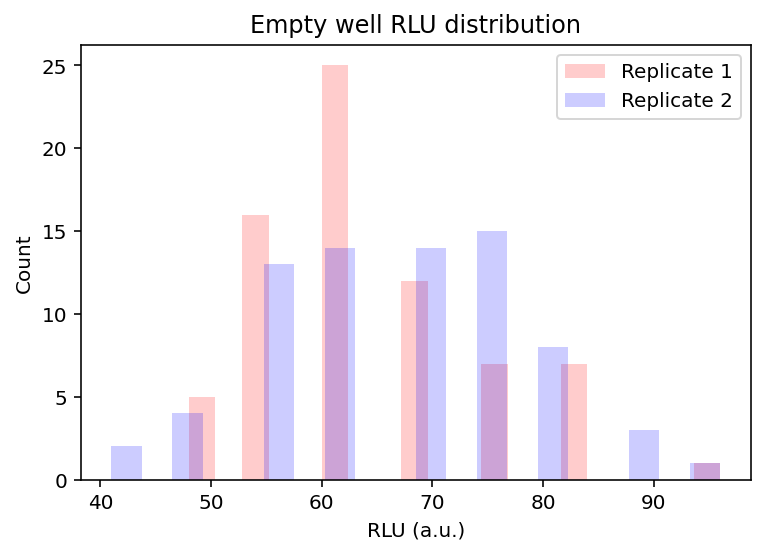

In [6]:
empty_well_keys = [(pla,rep,well) for pla,rep,well in res.keys() if well in ['G12','H12']]

rep_ew_r1_values = [v for k,v in res.items() if k in empty_well_keys and k[1] == 1 if v < 1000]
rep_ew_r2_values = [v for k,v in res.items() if k in empty_well_keys and k[1] == 2]


mean_r1 = np.mean(rep_ew_r1_values)
mean_r2 = np.mean(rep_ew_r2_values)
std_r1 = np.std(rep_ew_r1_values)
std_r2 = np.std(rep_ew_r2_values)

plt.figure()
plt.title('Empty well RLU distribution')
pd.Series(rep_ew_r1_values).plot.hist(bins=20, label='Replicate 1', color='r', alpha=0.2)
pd.Series(rep_ew_r2_values).plot.hist(bins=20, label='Replicate 2', color='b', alpha=0.2)
plt.xlabel('RLU (a.u.)')
plt.ylabel('Count')
plt.legend()
plt.savefig('../../../figures/000_global_analysis/nY2H_edotyping/empty_well_RLU.pdf')
plt.show()

In [7]:
print(mean_r1,mean_r2,std_r1,std_r2)

64.38356164383562 67.32432432432432 9.976177291031393 11.840274955842405


In [8]:
q = '''select * from vus.retest where standard_batch = "yN2Hapwt"'''

apwt_df = GetDFv2(q)

col = ['ad_orf_id', 'ad_symbol', 'db_orf_id','db_symbol', 'db_mut_id', 'variant_id','retest_pla','retest_pos',
       'N2H_raw_r01', 'N2H_raw_r02']

apwt_df = apwt_df[col].copy()

empty_well_df = pd.read_excel('20210328_yN2H_empty_wells.xlsx',sheet_name='Sheet2')
empty_well_df['replicate'] = empty_well_df.Plates.apply(lambda x: int(x.split('_')[2][-1]))
empty_well_df['plate'] = empty_well_df.Plates.apply(lambda x: int(x.split('_')[-1].replace('Plate','')))
empty_well_df['empty_wells'] = empty_well_df['Empty wells'].apply(lambda x: {f"{e.replace(' ','')[0]}{e.replace(' ','')[1:].zfill(2)}" for e in x.split(',')})
#empty_well_d = {(plate,rep):wells for plate, rep, wells in zip(empty_well_df.plate, empty_well_df.replicate, empty_well_df.empty_wells)}       
empty_well_set =  {(plate, rep, well) for plate, rep, wells in zip(empty_well_df.plate, empty_well_df.replicate, empty_well_df.empty_wells) for well in wells }

query = '''select orf_id, mut_id from vus.N2H_validation_nodes where collection = "rc4" '''
col = ['db_orf_id','db_mut_id']
rc4_mut_ids = GetDFv2(query,col)
rc4_mut_ids = set(zip(rc4_mut_ids.db_orf_id, rc4_mut_ids.db_mut_id))

apwt_df['empty_well_rep1'] = [(db_orf_id, db_mut_id) in rc4_mut_ids or (plate,1,retest_pos) in empty_well_set for db_orf_id, db_mut_id, plate, retest_pos in zip(apwt_df.db_orf_id, apwt_df.db_mut_id, apwt_df.retest_pla, apwt_df.retest_pos)]
apwt_df['empty_well_rep2'] = [(db_orf_id, db_mut_id) in rc4_mut_ids or (plate,2,retest_pos) in empty_well_set for db_orf_id, db_mut_id, plate, retest_pos in zip(apwt_df.db_orf_id, apwt_df.db_mut_id, apwt_df.retest_pla, apwt_df.retest_pos)]

apwt_df.head()

,ad_orf_id,ad_symbol,db_orf_id,db_symbol,db_mut_id,variant_id,retest_pla,retest_pos,N2H_raw_r01,N2H_raw_r02,empty_well_rep1,empty_well_rep2
0,71963,MBD3L1,2713,MLH1,981.0,allele,4,H05,96.0,82.0,False,False
1,11452,WASHC1,4723,TPM1,201730.0,allele,4,G05,336.0,103.0,False,False
2,361,GRAMD2B,3438,TMEM43,0.0,wt,4,F05,6558.0,2033.0,False,False
3,71892,TH,71892,TH,4005.0,allele,4,E05,1092.0,254.0,False,False
4,2500,ZNF212,2713,MLH1,0.0,wt,4,D05,124.0,82.0,False,False


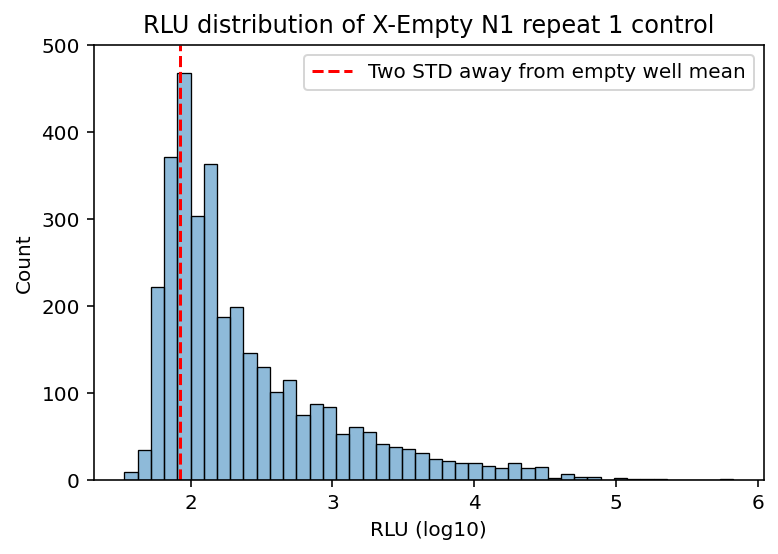

In [9]:
plt.figure()

plt.title('RLU distribution of X-Empty N1 repeat 1 control')
sns.histplot(data=apwt_df[(apwt_df.empty_well_rep1 == False)&(apwt_df.variant_id == 'empty_N1')], x=apwt_df.N2H_raw_r01.apply(np.log10), alpha=.5)

plt.vlines(x=np.log10((2*std_r1)+mean_r1),ymin=0, ymax=500, color='r', label='Two STD away from empty well mean', linestyle='--')

plt.ylim(0,500)
plt.xlabel('RLU (log10)')
plt.legend()

plt.show()

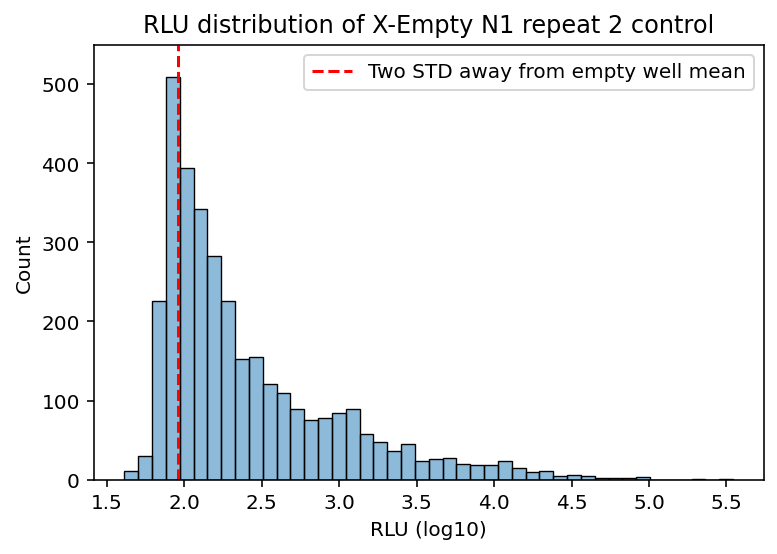

In [10]:
plt.figure()

plt.title('RLU distribution of X-Empty N1 repeat 2 control')
sns.histplot(data=apwt_df[(apwt_df.empty_well_rep2 == False)&(apwt_df.variant_id == 'empty_N1')], x=apwt_df.N2H_raw_r02.apply(np.log10), alpha=.5)

plt.vlines(x=np.log10((2*std_r2)+mean_r2),ymin=0, ymax=550, color='r', label='Two STD away from empty well mean', linestyle='--')

plt.ylim(0,550)
plt.xlabel('RLU (log10)')
plt.legend()

plt.show()

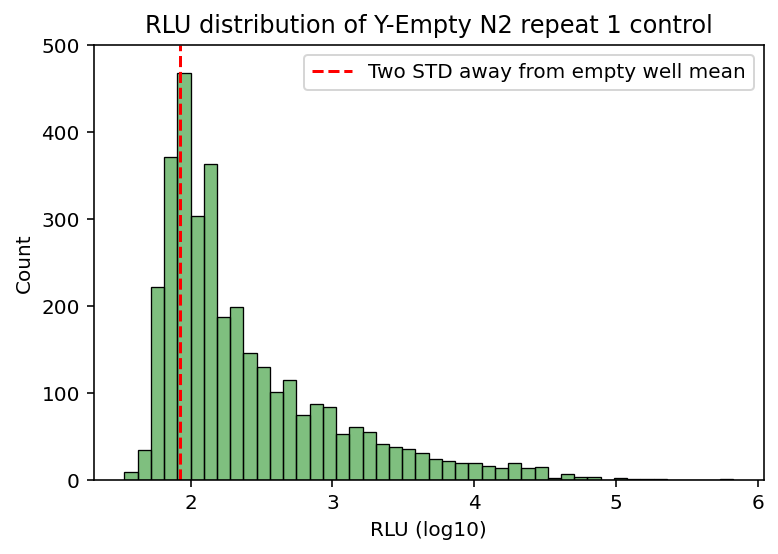

In [11]:
plt.figure()

plt.title('RLU distribution of Y-Empty N2 repeat 1 control')
sns.histplot(data=apwt_df[(apwt_df.empty_well_rep1 == False)&(apwt_df.variant_id == 'empty_N2')], x=apwt_df.N2H_raw_r01.apply(np.log10), alpha=.5, color='green')

plt.vlines(x=np.log10((2*std_r1)+mean_r1),ymin=0, ymax=500, color='r', label='Two STD away from empty well mean', linestyle='--')

plt.ylim(0,500)
plt.xlabel('RLU (log10)')
plt.legend()

plt.show()

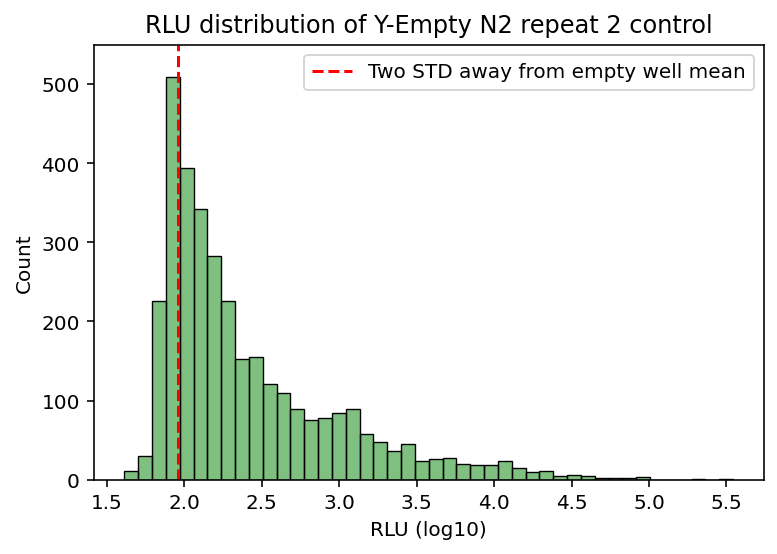

In [12]:
plt.figure()

plt.title('RLU distribution of Y-Empty N2 repeat 2 control')
sns.histplot(data=apwt_df[(apwt_df.empty_well_rep2 == False)&(apwt_df.variant_id == 'empty_N2')], x=apwt_df.N2H_raw_r02.apply(np.log10), alpha=.5, color='green')

plt.vlines(x=np.log10((2*std_r2)+mean_r2),ymin=0, ymax=550, color='r', label='Two STD away from empty well mean', linestyle='--')

plt.ylim(0,550)
plt.xlabel('RLU (log10)')
plt.legend()

plt.show()

## RLU-EN1-EN2

In [13]:
apwt_df.head()

,ad_orf_id,ad_symbol,db_orf_id,db_symbol,db_mut_id,variant_id,retest_pla,retest_pos,N2H_raw_r01,N2H_raw_r02,empty_well_rep1,empty_well_rep2
0,71963,MBD3L1,2713,MLH1,981.0,allele,4,H05,96.0,82.0,False,False
1,11452,WASHC1,4723,TPM1,201730.0,allele,4,G05,336.0,103.0,False,False
2,361,GRAMD2B,3438,TMEM43,0.0,wt,4,F05,6558.0,2033.0,False,False
3,71892,TH,71892,TH,4005.0,allele,4,E05,1092.0,254.0,False,False
4,2500,ZNF212,2713,MLH1,0.0,wt,4,D05,124.0,82.0,False,False


In [14]:
empty_N1_rep1_d = {(db,db_mut_id) if db_mut_id == db_mut_id else (db,999999):score for db, db_mut_id, score in zip(apwt_df[(apwt_df.variant_id == 'empty_N1')&(apwt_df.empty_well_rep1 == False)].db_orf_id, 
                                                                                                                   apwt_df[(apwt_df.variant_id == 'empty_N1')&(apwt_df.empty_well_rep1 == False)].db_mut_id, 
                                                                                                                   apwt_df[(apwt_df.variant_id == 'empty_N1')&(apwt_df.empty_well_rep1 == False)].N2H_raw_r01)}
empty_N2_rep1_d = dict(zip(apwt_df[(apwt_df.variant_id == 'empty_N2')&(apwt_df.empty_well_rep1 == False)].ad_orf_id, apwt_df[(apwt_df.variant_id == 'empty_N2')&(apwt_df.empty_well_rep1 == False)].N2H_raw_r01))

empty_N1_rep2_d = {(db,db_mut_id) if db_mut_id == db_mut_id else (db,999999):score for db, db_mut_id, score in zip(apwt_df[(apwt_df.variant_id == 'empty_N1')&(apwt_df.empty_well_rep2 == False)].db_orf_id, 
                                                                                                                   apwt_df[(apwt_df.variant_id == 'empty_N1')&(apwt_df.empty_well_rep2 == False)].db_mut_id, 
                                                                                                                   apwt_df[(apwt_df.variant_id == 'empty_N1')&(apwt_df.empty_well_rep2 == False)].N2H_raw_r02)}
empty_N2_rep2_d = dict(zip(apwt_df[(apwt_df.variant_id == 'empty_N2')&(apwt_df.empty_well_rep2 == False)].ad_orf_id, apwt_df[(apwt_df.variant_id == 'empty_N2')&(apwt_df.empty_well_rep2 == False)].N2H_raw_r02))
 

yN2H_normalized = apwt_df[apwt_df.variant_id.isin(['wt', 'allele', 'RRS','PRS'])].copy()

yN2H_normalized['db_orf_mut'] = [(orf_id,mut_id) if mut_id == mut_id else (orf_id,999999) for orf_id,mut_id in zip(yN2H_normalized.db_orf_id, yN2H_normalized.db_mut_id)]
yN2H_normalized['empty_N1_rep1'] = yN2H_normalized.db_orf_mut.map(empty_N1_rep1_d)
yN2H_normalized['empty_N2_rep1'] = yN2H_normalized.ad_orf_id.map(empty_N2_rep1_d)
yN2H_normalized['empty_N1_rep2'] = yN2H_normalized.db_orf_mut.map(empty_N1_rep2_d)
yN2H_normalized['empty_N2_rep2'] = yN2H_normalized.ad_orf_id.map(empty_N2_rep2_d)
yN2H_normalized.drop(columns='db_orf_mut',inplace=True)

yN2H_normalized['max_ctrl_r1'] = [max([en1,en2]) for en1, en2 in zip(yN2H_normalized.empty_N1_rep1, yN2H_normalized.empty_N2_rep1)]
yN2H_normalized['max_ctrl_r2'] = [max([en1,en2]) for en1, en2 in zip(yN2H_normalized.empty_N1_rep2, yN2H_normalized.empty_N2_rep2)]

yN2H_normalized['valid_r1'] = [ew == False and  en1 == en1 and en2 == en2 for ew, en1, en2 in zip(yN2H_normalized.empty_well_rep1, yN2H_normalized.empty_N1_rep1, yN2H_normalized.empty_N2_rep1)]
yN2H_normalized['valid_r2'] = [ew == False and  en1 == en1 and en2 == en2 for ew, en1, en2 in zip(yN2H_normalized.empty_well_rep2, yN2H_normalized.empty_N1_rep2, yN2H_normalized.empty_N2_rep2)]

yN2H_normalized['NLR1'] = [np.nan if not valid_r1 else N2H_raw_r01/max_ctrl_r1 for N2H_raw_r01,valid_r1,max_ctrl_r1 in zip(yN2H_normalized.N2H_raw_r01, yN2H_normalized.valid_r1, yN2H_normalized.max_ctrl_r1)]
yN2H_normalized['NLR2'] = [np.nan if not valid_r2 else N2H_raw_r02/max_ctrl_r2 for N2H_raw_r02,valid_r2,max_ctrl_r2 in zip(yN2H_normalized.N2H_raw_r02, yN2H_normalized.valid_r2, yN2H_normalized.max_ctrl_r2)]

mean_nlr_rrs_r1 = np.mean(yN2H_normalized[(yN2H_normalized.valid_r1)&(yN2H_normalized.variant_id == 'RRS')].NLR1)
mean_nlr_rrs_r2 = np.mean(yN2H_normalized[(yN2H_normalized.valid_r1)&(yN2H_normalized.variant_id == 'RRS')].NLR2)
std_nlr_rrs_r1 = np.std(yN2H_normalized[(yN2H_normalized.valid_r1)&(yN2H_normalized.variant_id == 'RRS')].NLR1)
std_nlr_rrs_r2 = np.std(yN2H_normalized[(yN2H_normalized.valid_r1)&(yN2H_normalized.variant_id == 'RRS')].NLR2)

d = {0:1,1:0}
yN2H_normalized['repeat_ratio'] = [[nlr1,nlr2][i%2]/[nlr1,nlr2][d[(i%2)]] for i,(nlr1, nlr2) in enumerate(zip(yN2H_normalized.NLR1, yN2H_normalized.NLR2))]
yN2H_normalized['repeat_ratio_log2'] = yN2H_normalized.repeat_ratio.apply(np.log2)

#yN2H_normalized['avg_NLR'] = [np.mean([e for e in [nlr1, nlr2] if e == e]) if nlr1 == nlr1 or nlr2 == nlr2 else np.nan for nlr1,nlr2 in zip(yN2H_normalized.NLR1, yN2H_normalized.NLR2)]
yN2H_normalized['avg_NLR'] = [np.mean([nlr1, nlr2]) for nlr1,nlr2 in zip(yN2H_normalized.NLR1, yN2H_normalized.NLR2)]

yN2H_normalized.head()

,ad_orf_id,ad_symbol,db_orf_id,db_symbol,db_mut_id,variant_id,retest_pla,retest_pos,N2H_raw_r01,N2H_raw_r02,empty_well_rep1,empty_well_rep2,empty_N1_rep1,empty_N2_rep1,empty_N1_rep2,empty_N2_rep2,max_ctrl_r1,max_ctrl_r2,valid_r1,valid_r2,NLR1,NLR2,repeat_ratio,repeat_ratio_log2,avg_NLR
0,71963,MBD3L1,2713,MLH1,981.0,allele,4,H05,96.0,82.0,False,False,62.0,199.0,76.0,144.0,199.0,144.0,True,True,0.482412,0.569444,0.847163,-0.239289,0.525928
1,11452,WASHC1,4723,TPM1,201730.0,allele,4,G05,336.0,103.0,False,False,117.0,137.0,124.0,110.0,137.0,124.0,True,True,2.452555,0.830645,0.338686,-1.561981,1.641600
2,361,GRAMD2B,3438,TMEM43,0.0,wt,4,F05,6558.0,2033.0,False,False,144.0,1174.0,220.0,1264.0,1174.0,1264.0,True,True,5.586031,1.608386,3.473066,1.796210,3.597208
3,71892,TH,71892,TH,4005.0,allele,4,E05,1092.0,254.0,False,False,227.0,144.0,302.0,213.0,227.0,302.0,True,True,4.810573,0.841060,0.174836,-2.515929,2.825816
4,2500,ZNF212,2713,MLH1,0.0,wt,4,D05,124.0,82.0,False,False,165.0,185.0,199.0,117.0,185.0,199.0,True,True,0.670270,0.412060,1.626632,0.701887,0.541165


## PRS RRS analysis

In [15]:
prs_rrs = yN2H_normalized[(yN2H_normalized.variant_id.isin(['PRS','RRS']))].copy()
prs_rrs.head()

,ad_orf_id,ad_symbol,db_orf_id,db_symbol,db_mut_id,variant_id,retest_pla,retest_pos,N2H_raw_r01,N2H_raw_r02,empty_well_rep1,empty_well_rep2,empty_N1_rep1,empty_N2_rep1,empty_N1_rep2,empty_N2_rep2,max_ctrl_r1,max_ctrl_r2,valid_r1,valid_r2,NLR1,NLR2,repeat_ratio,repeat_ratio_log2,avg_NLR
65,3535,EMD,5887,ARMC1,NaN,RRS,3,C09,1765.0,1009.0,False,False,220.0,5425.0,233.0,1820.0,5425.0,1820.0,True,True,0.325346,0.554396,0.586847,-0.768943,0.439871
77,8362,NKX2-5,9594,CSGALNACT2,NaN,RRS,3,G07,872.0,515.0,False,False,254.0,604.0,330.0,460.0,604.0,460.0,True,True,1.443709,1.119565,1.289526,0.366841,1.281637
179,6060,RFX3,8604,SEMA4G,NaN,RRS,2,D06,62.0,69.0,False,False,76.0,144.0,82.0,89.0,144.0,89.0,True,True,0.430556,0.775281,1.800652,0.848520,0.602918
188,8795,FANCA,7699,FANCC,NaN,PRS,2,C05,179.0,124.0,False,False,144.0,199.0,172.0,158.0,199.0,172.0,True,True,0.899497,0.720930,0.801481,-0.319260,0.810214
190,427,SLC25A6,5271,ZNF213,NaN,RRS,2,A05,76.0,69.0,False,False,89.0,330.0,103.0,165.0,330.0,165.0,True,True,0.230303,0.418182,1.815789,0.860597,0.324242


### Raw

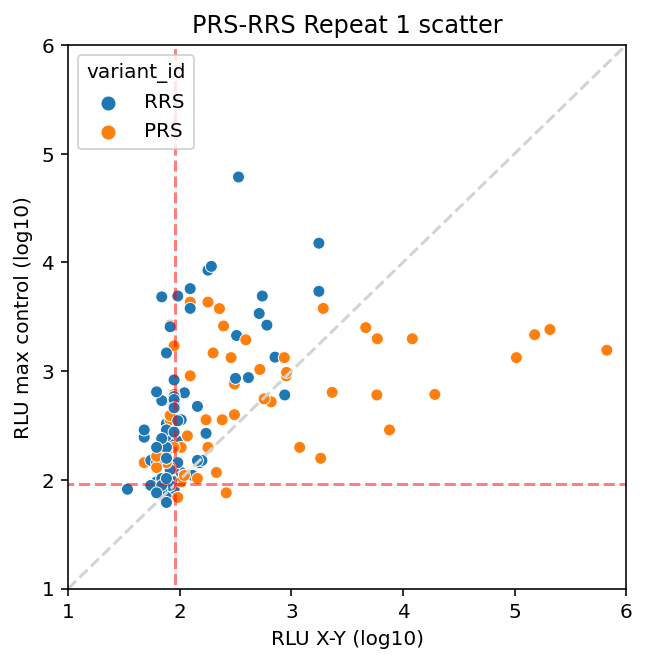

In [16]:
plt.figure(figsize=(5,5))
plt.title('PRS-RRS Repeat 1 scatter')
sns.scatterplot(data=prs_rrs[prs_rrs.valid_r1], 
                y=prs_rrs[prs_rrs.valid_r1].max_ctrl_r1.apply(np.log10), 
                x=prs_rrs[prs_rrs.valid_r1].N2H_raw_r01.apply(np.log10),
                hue='variant_id'
               )

plt.xlim(1,6)
plt.ylim(1,6)

plt.xlabel('RLU X-Y (log10)')
plt.ylabel('RLU max control (log10)')

plt.plot([1,6],[1,6], linestyle='--', color='lightgray')

plt.vlines(x=np.log10((2*std_r2)+mean_r2),ymin=0, ymax=550, color='r', label='Two STD away from empty well mean', linestyle='--',alpha=0.5)
plt.hlines(y=np.log10((2*std_r2)+mean_r2),xmin=0, xmax=550, color='r', label='Two STD away from empty well mean', linestyle='--',alpha=0.5)


plt.show()

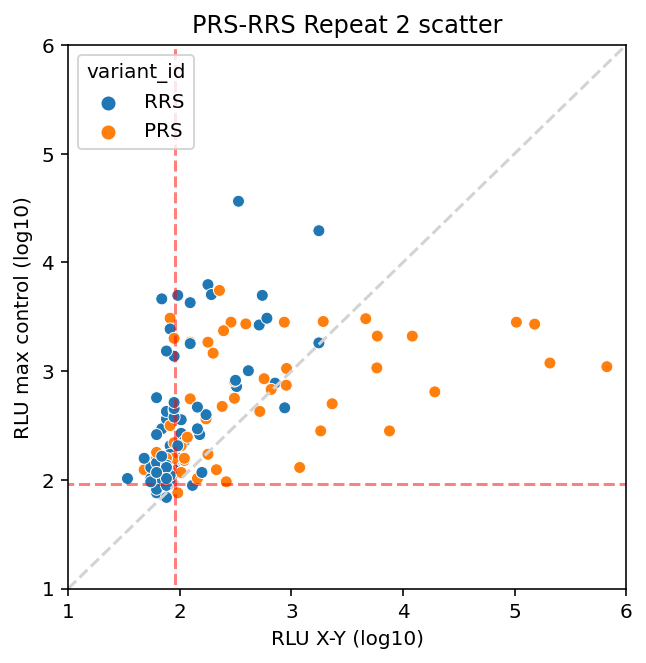

In [17]:
plt.figure(figsize=(5,5))
plt.title('PRS-RRS Repeat 2 scatter')
sns.scatterplot(data=prs_rrs[prs_rrs.valid_r2], 
                y=prs_rrs[prs_rrs.valid_r2].max_ctrl_r2.apply(np.log10), 
                x=prs_rrs[prs_rrs.valid_r2].N2H_raw_r01.apply(np.log10),
                hue='variant_id'
               )

plt.xlim(1,6)
plt.ylim(1,6)

plt.xlabel('RLU X-Y (log10)')
plt.ylabel('RLU max control (log10)')

plt.plot([1,6],[1,6], linestyle='--', color='lightgray')
plt.vlines(x=np.log10((2*std_r2)+mean_r2),ymin=0, ymax=550, color='r', label='Two STD away from empty well mean', linestyle='--',alpha=0.5)
plt.hlines(y=np.log10((2*std_r2)+mean_r2),xmin=0, xmax=550, color='r', label='Two STD away from empty well mean', linestyle='--',alpha=0.5)



plt.show()

### NLR

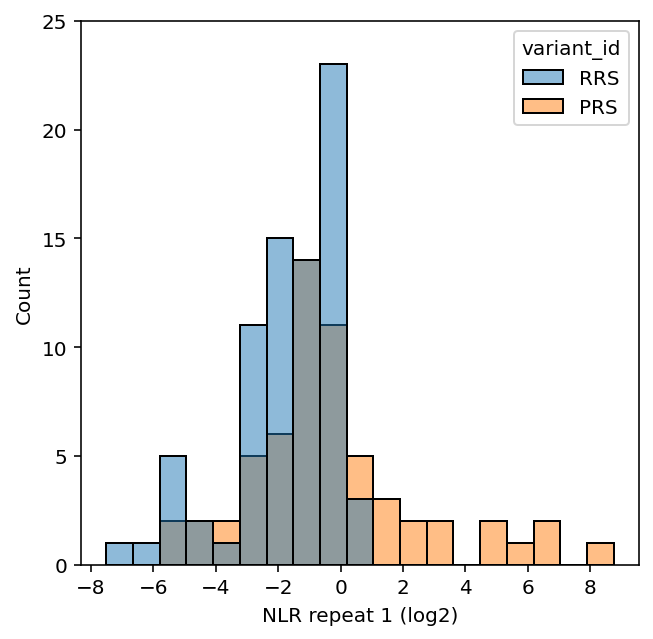

In [18]:
plt.figure(figsize=(5,5))

sns.histplot(data=prs_rrs[(prs_rrs.valid_r1==True)], 
                x=prs_rrs.NLR1.apply(np.log2), hue='variant_id'
               )

# mean_nlr_rrs_r1
# mean_nlr_rrs_r2
# std_nlr_rrs_r1
# std_nlr_rrs_r2

#plt.vlines(x=np.log2((2.23*std_nlr_rrs_r1)+mean_nlr_rrs_r1),ymin=0, ymax=550, color='r', label='2.23 STD away from empty well mean', linestyle='--',alpha=0.5)
#plt.vlines(x=np.log2(2),ymin=0, ymax=550, color='r', label='2.23 STD away from empty well mean', linestyle='--',alpha=0.5)


#plt.xlim(-8,9.5)
plt.ylim(0,25)
plt.xlabel('NLR repeat 1 (log2)')

plt.show()

In [19]:
(2.23*std_nlr_rrs_r1)+mean_nlr_rrs_r1

1.2345605042756538

In [20]:
(2.23*std_nlr_rrs_r2)+mean_nlr_rrs_r2

1.5734682332012864

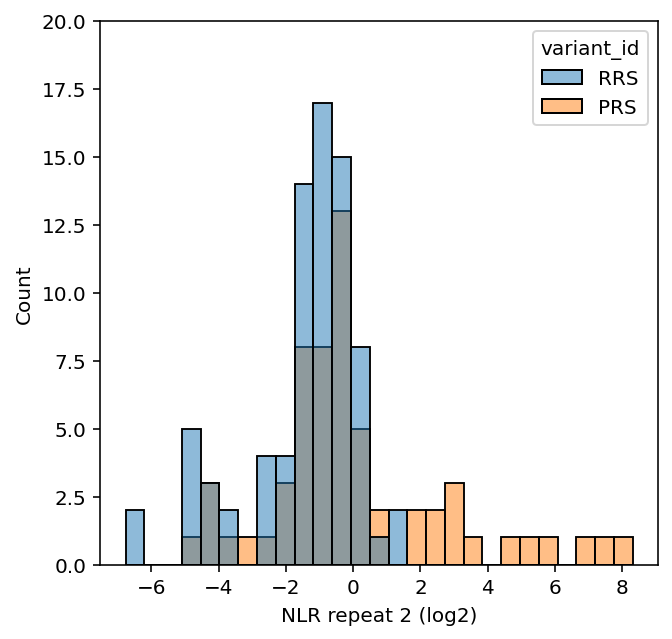

In [21]:
plt.figure(figsize=(5,5))

sns.histplot(data=prs_rrs[(prs_rrs.valid_r2==True)], 
                x=prs_rrs.NLR2.apply(np.log2), hue='variant_id'
               )

# mean_nlr_rrs_r1
# mean_nlr_rrs_r2
# std_nlr_rrs_r1
# std_nlr_rrs_r2

#plt.vlines(x=np.log2((2.23*std_nlr_rrs_r2)+mean_nlr_rrs_r2),ymin=0, ymax=550, color='r', label='2.23 STD away from empty well mean', linestyle='--',alpha=0.5)
#plt.vlines(x=np.log2(2),ymin=0, ymax=550, color='r', label='2.23 STD away from empty well mean', linestyle='--',alpha=0.5)

#plt.xlim(-8,9.5)
plt.ylim(0,20)
plt.xlabel('NLR repeat 2 (log2)')

plt.show()

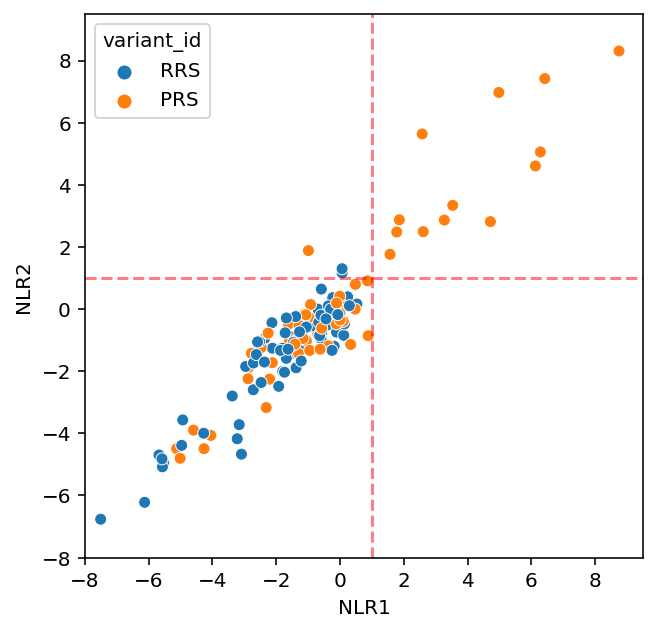

In [22]:
plt.figure(figsize=(5,5))

sns.scatterplot(data=prs_rrs[(prs_rrs.valid_r1==True)&(prs_rrs.valid_r2==True)], 
                x=prs_rrs.NLR1.apply(np.log2), 
                y=prs_rrs.NLR2.apply(np.log2),hue='variant_id'
               )

# mean_nlr_rrs_r1
# mean_nlr_rrs_r2
# std_nlr_rrs_r1
# std_nlr_rrs_r2

# plt.vlines(x=np.log2((2.23*std_nlr_rrs_r1)+mean_nlr_rrs_r1),ymin=-8, ymax=550, color='r', label='2.23 STD away from empty well mean', linestyle='--',alpha=0.5)
# plt.hlines(y=np.log2((2.23*std_nlr_rrs_r2)+mean_nlr_rrs_r2),xmin=-8, xmax=550, color='r', label='2.23 STD away from empty well mean', linestyle='--',alpha=0.5)
plt.vlines(x=np.log2(2),ymin=-8, ymax=550, color='r', label='2.23 STD away from empty well mean', linestyle='--',alpha=0.5)
plt.hlines(y=np.log2(2),xmin=-8, xmax=550, color='r', label='2.23 STD away from empty well mean', linestyle='--',alpha=0.5)



plt.xlim(-8,9.5)
plt.ylim(-8,9.5)

plt.show()

## Allele WT analysis

(-7.0, 10.0)

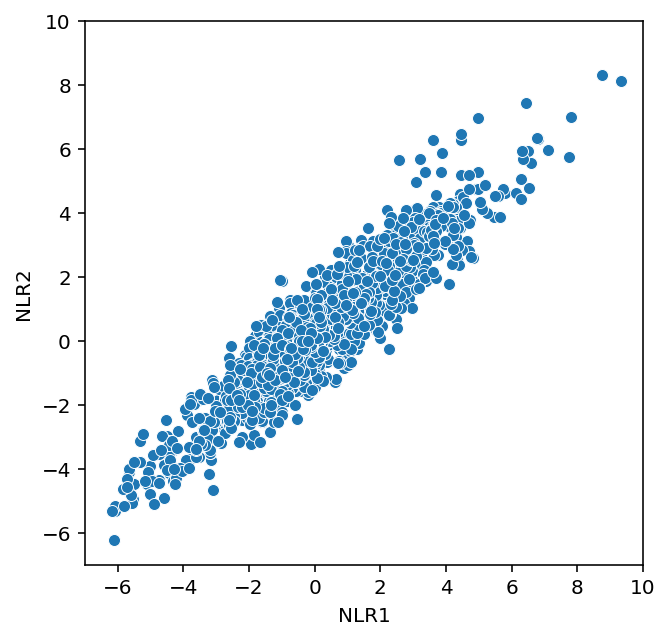

In [23]:
plt.figure(figsize=(5,5))
sns.scatterplot(data=yN2H_normalized, x=yN2H_normalized.NLR1.apply(np.log2),y=yN2H_normalized.NLR2.apply(np.log2))

plt.xlim(-7,10)
plt.ylim(-7,10)

0.7305259221170665 1.1842762956867572


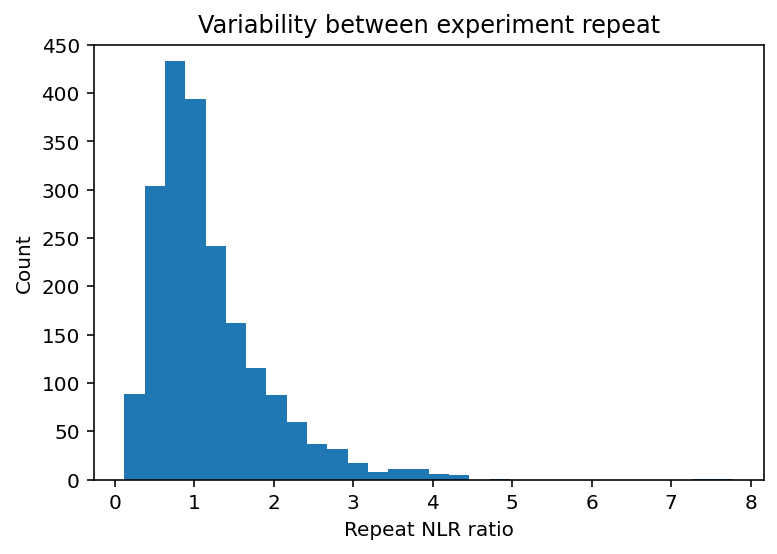

In [24]:
std_ratio = np.std(yN2H_normalized.repeat_ratio)
mean_ratio = np.mean(yN2H_normalized.repeat_ratio)

print(std_ratio,mean_ratio)

plt.figure()
plt.title('Variability between experiment repeat')
fig = yN2H_normalized.repeat_ratio.plot.hist(bins=30)
plt.xlabel('Repeat NLR ratio')
plt.ylabel('Count')

plt.ylim(0,450)

plt.show()

0.8203905402711511 0.011073563891563235


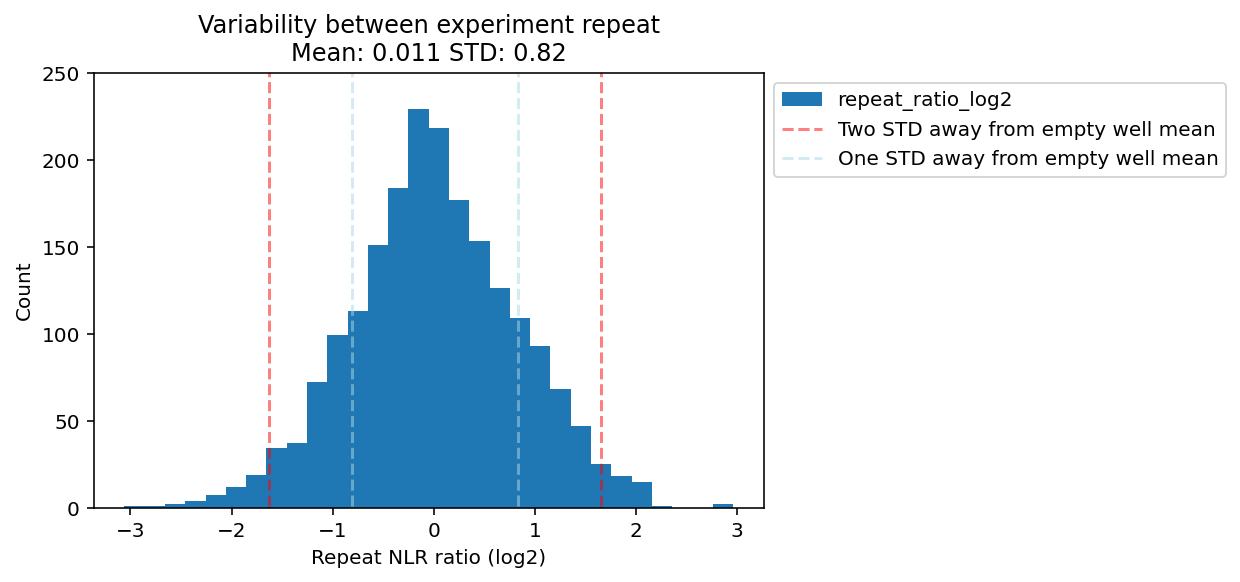

In [25]:
std_ratio = np.std(yN2H_normalized.repeat_ratio_log2)
mean_ratio = np.mean(yN2H_normalized.repeat_ratio_log2)

print(std_ratio,mean_ratio)

plt.figure()
plt.title(f'Variability between experiment repeat\nMean: {round(mean_ratio,3)} STD: {round(std_ratio,3)}')
fig = yN2H_normalized.repeat_ratio_log2.plot.hist(bins=30)
plt.xlabel('Repeat NLR ratio (log2)')
plt.ylabel('Count')

plt.vlines(x=(2*std_ratio)+mean_ratio,ymin=-8, ymax=550, color='r', linestyle='--',alpha=0.5)
plt.vlines(x=(-2*std_ratio)+mean_ratio,ymin=-8, ymax=550, color='r', label='Two STD away from empty well mean', linestyle='--',alpha=0.5)

plt.vlines(x=(1*std_ratio)+mean_ratio,ymin=-8, ymax=550, color='lightblue', linestyle='--',alpha=0.5)
plt.vlines(x=(-1*std_ratio)+mean_ratio,ymin=-8, ymax=550, color='lightblue', label='One STD away from empty well mean', linestyle='--',alpha=0.5)


plt.ylim(0,250)
plt.legend(loc='upper left',bbox_to_anchor=(1, 1))

plt.show()

0.8047616971873113 -0.001375668602746857


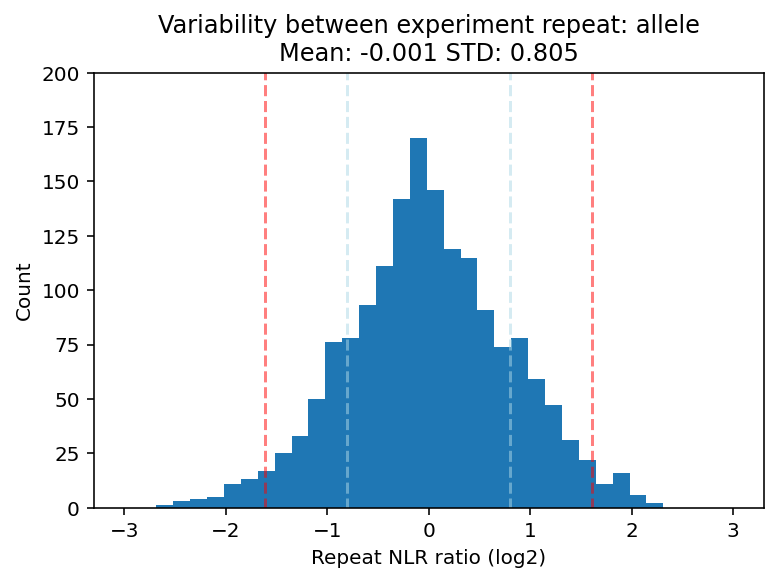

0.8979963981550538 0.07331636405264863


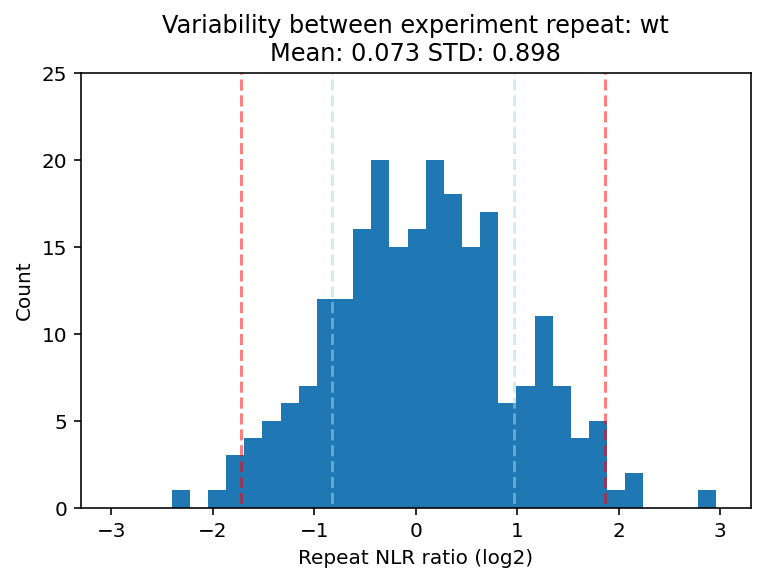

0.9773885804013552 0.07876541677737664


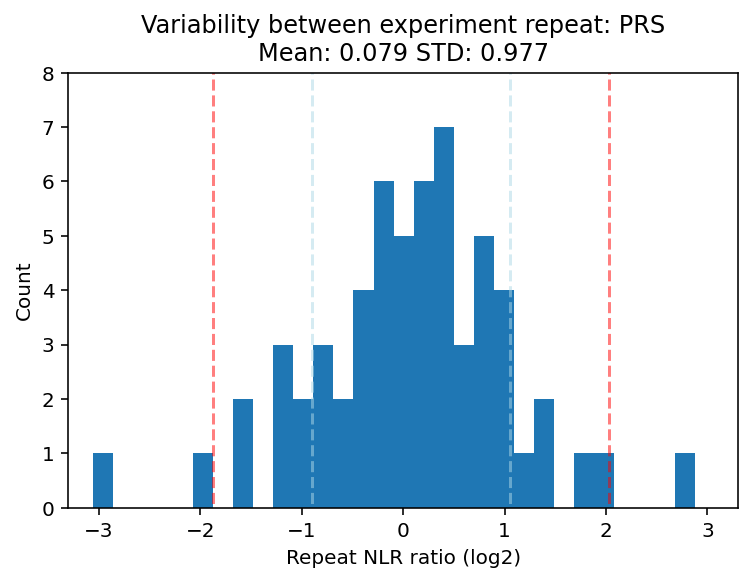

0.7580916055768345 0.037743874057309446


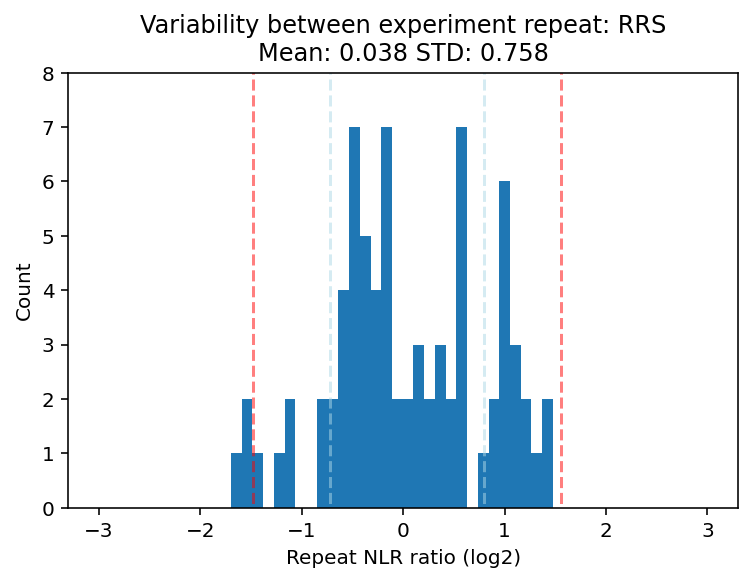

In [26]:
for ylim, variant_id in zip([200,25,8,8],['allele','wt','PRS','RRS']):
    std_ratio = np.std(yN2H_normalized[yN2H_normalized.variant_id == variant_id].repeat_ratio_log2)
    mean_ratio = np.mean(yN2H_normalized[yN2H_normalized.variant_id == variant_id].repeat_ratio_log2)

    print(std_ratio,mean_ratio)

    plt.figure()
    plt.title(f'Variability between experiment repeat: {variant_id}\nMean: {round(mean_ratio,3)} STD: {round(std_ratio,3)}')
    fig = yN2H_normalized[yN2H_normalized.variant_id == variant_id].repeat_ratio_log2.plot.hist(bins=30)
    plt.xlabel('Repeat NLR ratio (log2)')
    plt.ylabel('Count')

    plt.vlines(x=(2*std_ratio)+mean_ratio,ymin=-8, ymax=550, color='r', linestyle='--',alpha=0.5)
    plt.vlines(x=(-2*std_ratio)+mean_ratio,ymin=-8, ymax=550, color='r', label='Two STD away from empty well mean', linestyle='--',alpha=0.5)

    plt.vlines(x=(1*std_ratio)+mean_ratio,ymin=-8, ymax=550, color='lightblue', linestyle='--',alpha=0.5)
    plt.vlines(x=(-1*std_ratio)+mean_ratio,ymin=-8, ymax=550, color='lightblue', label='One STD away from empty well mean', linestyle='--',alpha=0.5)



    plt.ylim(0,ylim)
    plt.xlim(-3.3,3.3)
    
    #plt.legend(loc='upper left',bbox_to_anchor=(1, 1))

    plt.show()

(-7.0, 10.0)

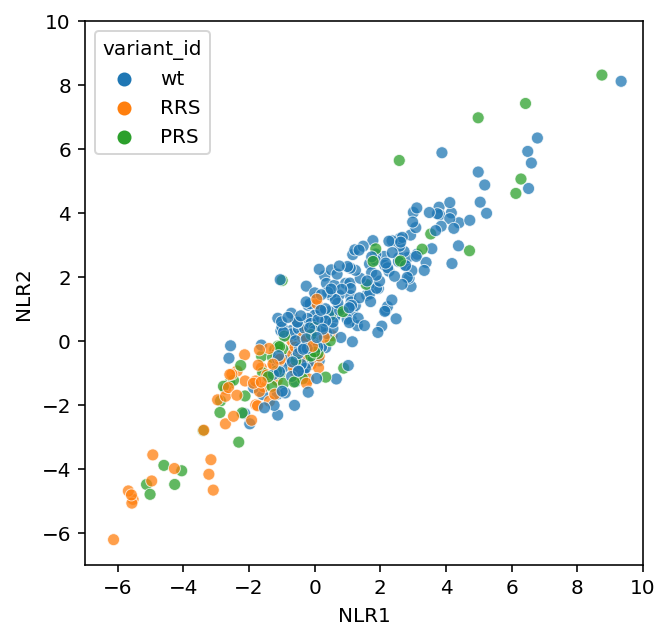

In [27]:
plt.figure(figsize=(5,5))
sns.scatterplot(data=yN2H_normalized[yN2H_normalized.variant_id != 'allele'], x=yN2H_normalized.NLR1.apply(np.log2),y=yN2H_normalized.NLR2.apply(np.log2), hue='variant_id', alpha=0.75)

#x1, y1 = [-1, 12], [1, 4]
#plt.plot(x1, y1, color='lightgray', linestyle='--', alpha=0.5)

plt.xlim(-7,10)
plt.ylim(-7,10)

### Allele-WT df

In [28]:
mut_d

{(2, 6.0): ('160G>C', 'Val54Leu', 'Pathogenic'),
 (2, 73.0): ('670C>T', 'Leu224Phe', 'Pathogenic'),
 (2, 113.0): ('887G>A', 'Arg296Gln', 'Pathogenic'),
 (2, 231.0): ('1448T>C', 'Leu483Pro', 'Conflicting'),
 (25, 252.0): ('328C>G', 'Leu110Val', 'Conflicting'),
 (25, 200008.0): ('328C>G', 'Leu110Val', 'Conflicting'),
 (25, 253.0): ('458G>A', 'Arg153Gln', 'VUS'),
 (25, 200009.0): ('458G>A', 'Arg153Gln', 'VUS'),
 (138, 276.0): ('278T>C', 'Leu93Pro', 'Pathogenic'),
 (138, 277.0): ('586C>T', 'Arg196Cys', 'Pathogenic'),
 (167, 376.0): ('116G>A', 'Arg39His', 'Conflicting'),
 (167, 378.0): ('350A>C', 'Asn117Thr', 'Pathogenic'),
 (167, 385.0): ('635G>A', 'Arg212Gln', 'Pathogenic'),
 (167, 390.0): ('874A>G', 'Arg292Gly', 'Pathogenic'),
 (187, 393.0): ('271G>A', 'Gly91Arg', 'Pathogenic'),
 (212, 670.0): ('446G>A', 'Arg149Gln', 'VUS'),
 (222, 673.0): ('593A>G', 'Asp198Gly', 'Pathogenic'),
 (253, 708.0): ('386A>G', 'Asp129Gly', 'Pathogenic'),
 (253, 709.0): ('619G>A', 'Glu207Lys', 'Pathogenic'),
 (2

In [29]:
#mean NLR
#allele-wt ratio
#z-score perturbation

#two metrics: detection (above RRS, noise) + perturbation quantification allele/wt zscore
#NA if not 


allele_df = yN2H_normalized.query("variant_id == 'allele' and ~avg_NLR.isnull()").copy()
allele_df['nt_change'] = [mut_d[orf_id,mut_id][0] for orf_id, mut_id in zip(allele_df.db_orf_id, allele_df.db_mut_id)]
allele_df['aa_change'] = [mut_d[orf_id,mut_id][1] for orf_id, mut_id in zip(allele_df.db_orf_id, allele_df.db_mut_id)]
allele_df['clinical_significance'] = [mut_d[orf_id,mut_id][2] for orf_id, mut_id in zip(allele_df.db_orf_id, allele_df.db_mut_id)]

df = yN2H_normalized.query("variant_id == 'wt'")
wt_NLR_d = dict(zip(df.db_orf_id, df.avg_NLR))
allele_df['avg_WT_NLR'] = allele_df.db_orf_id.map(wt_NLR_d)
allele_df = allele_df[~allele_df.avg_WT_NLR.isnull()].copy() #remove only one allele-WT
allele_df['AWT_ratio'] = allele_df.avg_NLR / allele_df.avg_WT_NLR

df = yN2H_normalized.query("variant_id == 'RRS'")
l = [np.mean([nlr1,nlr2]) for nlr1,nlr2 in zip(df.NLR1, df.NLR2) if nlr1 == nlr1 and nlr2 == nlr2]
std_rrs, mean_rrs = np.std(l), np.mean(l)
allele_df['z_WT_NLR'] = allele_df.avg_WT_NLR.apply(lambda x: (x-mean_rrs)/std_rrs)
allele_df['WT_detected'] = allele_df.z_WT_NLR.apply(lambda x: x >= 2.23)

std_ratio = np.std(yN2H_normalized.repeat_ratio_log2)
mean_ratio = np.mean(yN2H_normalized.repeat_ratio_log2)
allele_df['z_perturbation'] = allele_df.AWT_ratio.apply(lambda x: (np.log2(x)-mean_ratio)/std_ratio)
#allele_df['z_cat'] = allele_df.z_perturbation.apply(lambda x: 'increase_ppi' if x>=3 else 'decrease_ppi' if x<=-3 else 'no_perturbation')
allele_df['z_cat'] = ['not_detected' if not wt_detected else 'increase_ppi' if zp>=2 else 'decrease_ppi' if zp<=-2 else 'no_perturbation' for zp,wt_detected in zip(allele_df.z_perturbation, allele_df.WT_detected)] 

allele_df.head()

,ad_orf_id,ad_symbol,db_orf_id,db_symbol,db_mut_id,variant_id,retest_pla,retest_pos,N2H_raw_r01,N2H_raw_r02,empty_well_rep1,empty_well_rep2,empty_N1_rep1,empty_N2_rep1,empty_N1_rep2,empty_N2_rep2,max_ctrl_r1,max_ctrl_r2,valid_r1,valid_r2,NLR1,NLR2,repeat_ratio,repeat_ratio_log2,avg_NLR,nt_change,aa_change,clinical_significance,avg_WT_NLR,AWT_ratio,z_WT_NLR,WT_detected,z_perturbation,z_cat
0,71963,MBD3L1,2713,MLH1,981.0,allele,4,H05,96.0,82.0,False,False,62.0,199.0,76.0,144.0,199.0,144.0,True,True,0.482412,0.569444,0.847163,-0.239289,0.525928,2038T>C,Cys680Arg,Pathogenic,0.613339,0.857483,0.267141,False,-0.283881,not_detected
1,11452,WASHC1,4723,TPM1,201730.0,allele,4,G05,336.0,103.0,False,False,117.0,137.0,124.0,110.0,137.0,124.0,True,True,2.452555,0.830645,0.338686,-1.561981,1.641600,160G>A,Glu54Lys,Pathogenic,0.940757,1.744978,1.144436,False,0.965559,not_detected
3,71892,TH,71892,TH,4005.0,allele,4,E05,1092.0,254.0,False,False,227.0,144.0,302.0,213.0,227.0,302.0,True,True,4.810573,0.841060,0.174836,-2.515929,2.825816,848C>T,Thr283Met,VUS,26.565896,0.106370,69.805558,True,-3.954104,decrease_ppi
7,71892,TH,71892,TH,4016.0,allele,4,A05,2987.0,1490.0,False,False,151.0,144.0,151.0,213.0,151.0,213.0,True,True,19.781457,6.995305,2.827819,1.499690,13.388381,605G>A,Arg202His,Pathogenic,26.565896,0.503969,69.805558,True,-1.218526,no_perturbation
8,11671,FAN1,2713,MLH1,889.0,allele,4,H04,103.0,76.0,False,False,137.0,89.0,185.0,103.0,137.0,185.0,True,True,0.751825,0.410811,0.546418,-0.871922,0.581318,1744C>G,Leu582Val,VUS,0.613339,0.947791,0.267141,False,-0.107793,not_detected


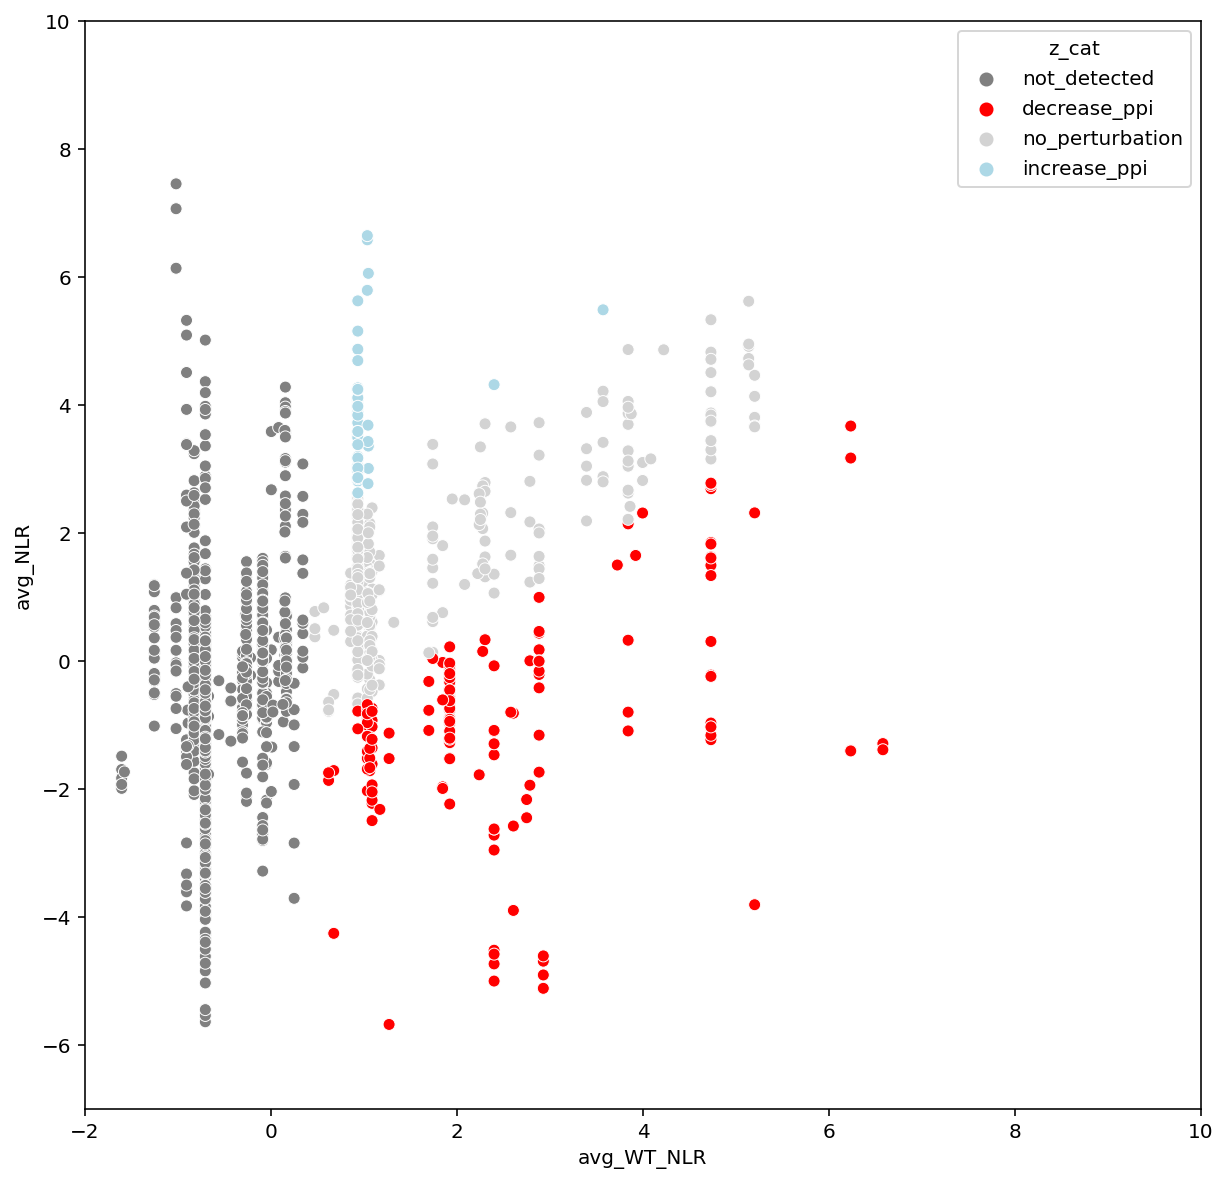

In [30]:
plt.figure(figsize=(10,10))
ax = sns.scatterplot(data=allele_df, x=allele_df.avg_WT_NLR.apply(np.log2), 
                     y=allele_df.avg_NLR.apply(np.log2), hue='z_cat',palette={'not_detected':'gray',
                                                                              'increase_ppi':'lightblue',
                                                                              'decrease_ppi':'red',
                                                                              'no_perturbation':'lightgray'}
                    )


plt.xlim(-2,10)
plt.ylim(-7,10)
plt.show()

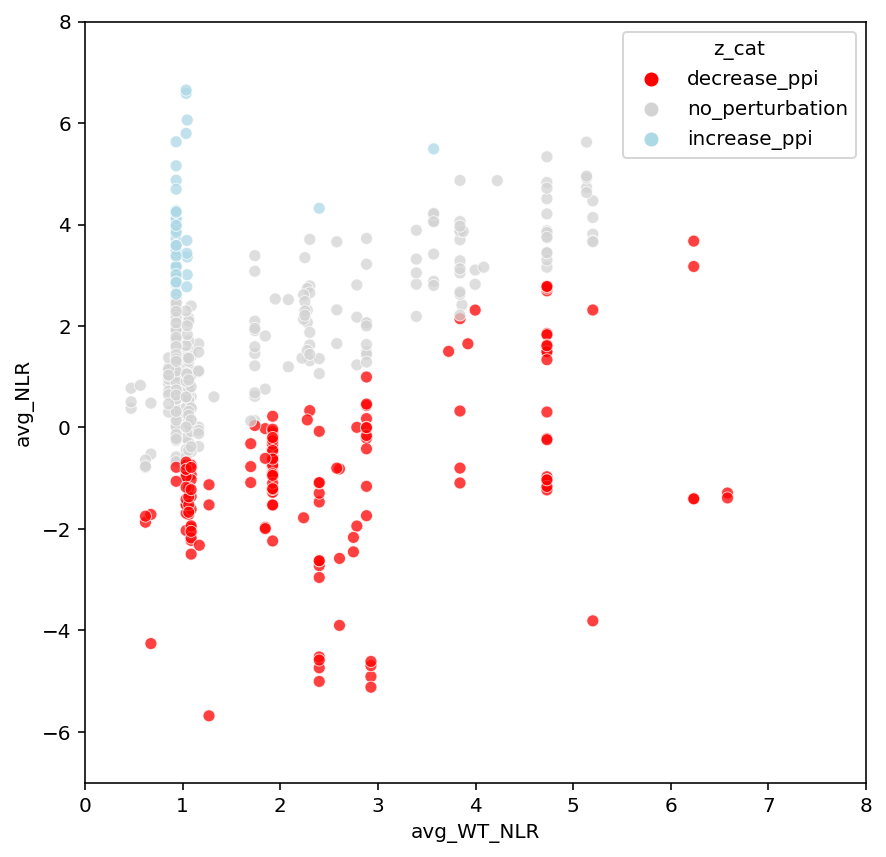

In [31]:
plt.figure(figsize=(7,7))
ax = sns.scatterplot(data=allele_df[allele_df.WT_detected], x=allele_df.avg_WT_NLR.apply(np.log2),alpha=0.75,
                     y=allele_df.avg_NLR.apply(np.log2), hue='z_cat',palette={'not_detected':'gray',
                                                                              'increase_ppi':'lightblue',
                                                                              'decrease_ppi':'red',
                                                                              'no_perturbation':'lightgray'}
                    )


plt.xlim(0,8)
plt.ylim(-7,8)
plt.show()

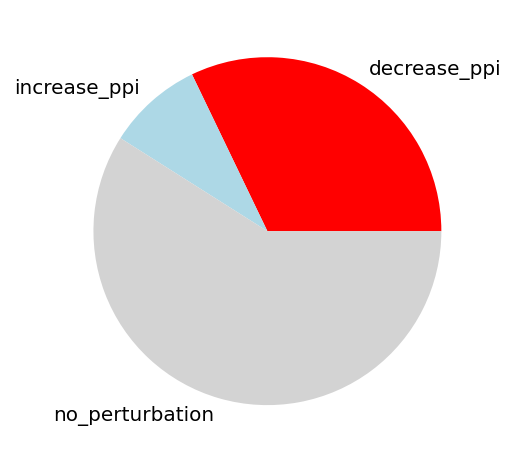

In [32]:
allele_df[allele_df.WT_detected].z_cat.value_counts().sort_index().plot.pie(colors=['red','lightblue','lightgray','gray']);
plt.ylabel('');

In [33]:
allele_df[(allele_df.WT_detected)].clinical_significance.value_counts()

Pathogenic     438
VUS             58
Conflicting     20
Benign          11
Name: clinical_significance, dtype: int64

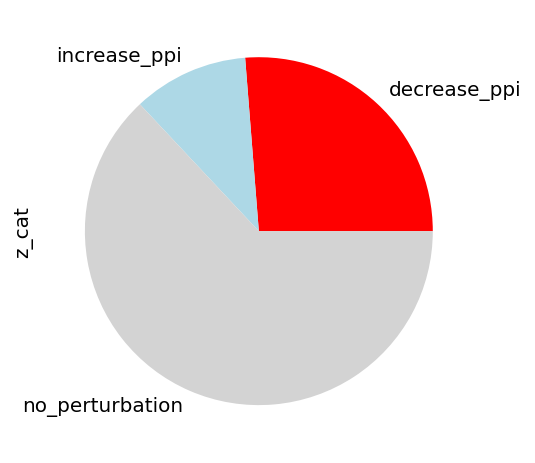

In [34]:
allele_df[(allele_df.WT_detected)&(allele_df.clinical_significance == 'Pathogenic')].z_cat.value_counts().sort_index().plot.pie(colors=['red','lightblue','lightgray','gray']);

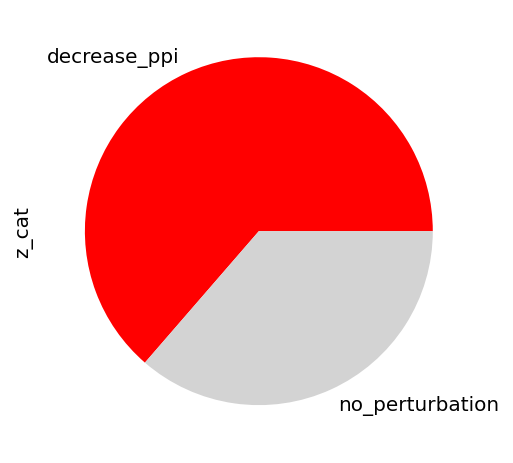

In [35]:
allele_df[(allele_df.WT_detected)&(allele_df.clinical_significance == 'Benign')].z_cat.value_counts().sort_index().plot.pie(colors=['red','lightgray','gray']);

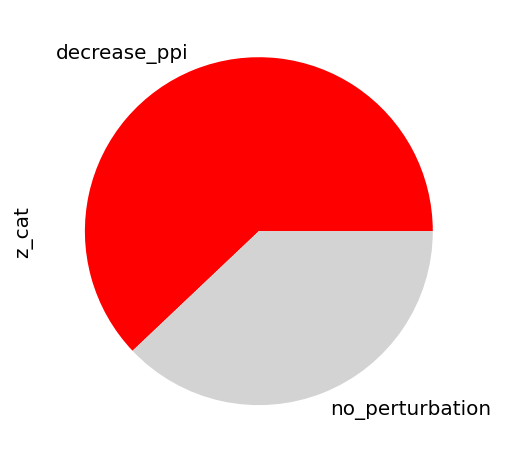

In [36]:
allele_df[(allele_df.WT_detected)&(allele_df.clinical_significance == 'VUS')].z_cat.value_counts().sort_index().plot.pie(colors=['red','lightgray','gray']);



In [37]:
allele_df[(allele_df.WT_detected)&(allele_df.clinical_significance == 'Benign')]

,ad_orf_id,ad_symbol,db_orf_id,db_symbol,db_mut_id,variant_id,retest_pla,retest_pos,N2H_raw_r01,N2H_raw_r02,empty_well_rep1,empty_well_rep2,empty_N1_rep1,empty_N2_rep1,empty_N1_rep2,empty_N2_rep2,max_ctrl_r1,max_ctrl_r2,valid_r1,valid_r2,NLR1,NLR2,repeat_ratio,repeat_ratio_log2,avg_NLR,nt_change,aa_change,clinical_significance,avg_WT_NLR,AWT_ratio,z_WT_NLR,WT_detected,z_perturbation,z_cat
28,361,GRAMD2B,3438,TMEM43,201175.0,allele,4,C02,6641.0,1669.0,False,False,165.0,1174.0,144.0,1264.0,1174.0,1264.0,True,True,5.656729,1.320411,0.233423,-2.098981,3.488570,82C>T,Arg28Trp,Benign,3.597208,0.969799,8.262250,True,-0.067426,no_perturbation
61,281,MVK,281,MVK,5.0,allele,3,G09,1257.0,872.0,False,False,350.0,288.0,426.0,405.0,350.0,426.0,True,True,3.591429,2.046948,0.569954,-0.811083,2.819188,155G>A,Ser52Asn,Benign,2.125617,1.326292,4.319204,True,0.483092,no_perturbation
464,137,SNAP29,71592,TRAF3,206017.0,allele,11,H09,103.0,103.0,False,False,62.0,213.0,76.0,158.0,213.0,158.0,True,True,0.483568,0.651899,0.741784,-0.430929,0.567733,352C>T,Arg118Trp,Benign,6.093278,0.093174,14.950328,True,-4.187038,decrease_ppi
475,361,GRAMD2B,3438,TMEM43,201180.0,allele,11,E08,1277.0,1112.0,False,False,89.0,1174.0,96.0,1264.0,1174.0,1264.0,True,True,1.087734,0.879747,1.236417,0.306166,0.983741,829A>T,Thr277Ser,Benign,3.597208,0.273473,8.262250,True,-2.293544,decrease_ppi
510,2533,PYGB,55246,PYGL,3236.0,allele,11,A04,4546.0,3282.0,False,False,227.0,117.0,247.0,199.0,227.0,247.0,True,True,20.026432,13.287449,1.507169,0.591841,16.656941,176C>T,Thr59Met,Benign,14.330993,1.162302,37.022822,True,0.250992,no_perturbation
1416,7201,RAD51D,13571,XRCC2,218098.0,allele,19,E02,508.0,508.0,False,False,96.0,144.0,69.0,185.0,144.0,185.0,True,True,3.527778,2.745946,1.284722,0.361456,3.136862,808T>G,Phe270Val,Benign,15.157188,0.206955,39.236567,True,-2.783652,decrease_ppi
2042,9637,TRAF2,71592,TRAF3,206017.0,allele,29,D11,62.0,82.0,False,False,62.0,391.0,76.0,467.0,391.0,467.0,True,True,0.158568,0.175589,0.903063,-0.147102,0.167078,352C>T,Arg118Trp,Benign,6.093278,0.027420,14.950328,True,-6.338074,decrease_ppi
2471,6281,KCNJ15,100016069,KCNJ2,2635.0,allele,25,E03,82.0,117.0,False,False,96.0,89.0,137.0,103.0,96.0,137.0,True,True,0.854167,0.854015,0.999822,-0.000257,0.854091,773T>C,Ile258Thr,Benign,3.791671,0.225254,8.783302,True,-2.634655,decrease_ppi
2525,281,MVK,281,MVK,28.0,allele,24,E08,316.0,378.0,False,False,124.0,288.0,179.0,405.0,288.0,405.0,True,True,1.097222,0.933333,0.850633,-0.233391,1.015278,1156G>A,Asp386Asn,Benign,2.125617,0.477639,4.319204,True,-1.312888,no_perturbation
3044,70436,IP6K3,71592,TRAF3,206017.0,allele,34,B02,82.0,89.0,False,False,62.0,2088.0,76.0,941.0,2088.0,941.0,True,True,0.039272,0.094580,2.408336,1.268037,0.066926,352C>T,Arg118Trp,Benign,6.093278,0.010984,14.950328,True,-7.946921,decrease_ppi


## Comparisons with qY2H

In [38]:
from load_pdest_stability import load_pdest_dataset


help(load_pdest_dataset)

Help on function load_pdest_dataset in module load_pdest_stability:

load_pdest_dataset(dataset='avg_allele', mode='read_csv', update=False)
    dataset:
        - avg_allele: only data for alleles, with WT score, allele/wt Z-score, for each valid data point
        - pDEST_DUAL_avg: all average GFP/mCherry data for each well of the experiment
        - raw_data: all data for
    
    mode:
        - read_csv: read csv file rather than reprocess the raw data
        - reprocess: reprocess the whole data
    
    rewrite:
        - if True: update pdest dual data files saved in data folder



In [39]:
pdest_df  = load_pdest_dataset()
pdest_df['zcat'] = [c if s==s else np.nan for s,c in zip(pdest_df.zscore, pdest_df.zcat)]
pdest_df.rename(columns={'orf_id':'db_orf_id','mut_id':'db_mut_id','allele_wt_ratio':'pdest_awr','zscore':'pdest_zscore','zcat':'pdest_zcat'},inplace=True)
pdest_df.head()

,avg_gfp,avg_mcherry,avg_GFP_mCherry_ratio,pla,well,coordinates,n_cells,db_orf_id,db_mut_id,node_type,nt_change,aa_change,clinical_significance,symbol,valid_well,z_pdest_empty,z_pdest_gfp,valid_gfp_mcherry_ratio,wt_GFP_mCherry_ratio,pdest_awr,pdest_zscore,pdest_zcat
0,38.548163,7812.079547,0.010358,24,B07,"(24, 'B07')",8786,52920.0,2670.0,allele,388G>A,Gly130Ser,VUS,LITAF,True,-0.114591,-0.709508,NaN,NaN,NaN,NaN,NaN
1,651.596799,4750.119233,0.214581,8,A10,"(8, 'A10')",9387,3020.0,214471.0,allele,937G>A,Glu313Lys,Pathogenic,CHN1,True,11.094285,-0.075601,NaN,0.991226,0.216481,-2.711436,-2.0
2,1732.782852,6722.060197,0.365943,9,F01,"(9, 'F01')",8908,13113.0,21930.0,allele,427C>T,Arg143Cys,Conflicting,MCEE,True,19.401841,0.394226,NaN,0.448492,0.815940,-0.752219,0.0
3,481.091263,5965.903765,0.127281,22,D05,"(22, 'D05')",8739,4870.0,900200.0,allele,1567G>T,Val523Phe,NaN,KRT6A,True,6.302756,-0.346581,NaN,0.142704,0.891918,-0.503900,0.0
4,536.230753,1949.598159,0.395380,13,D07,"(13, 'D07')",8747,7652.0,1813.0,allele,875G>A,Arg292His,Pathogenic,STXBP1,True,21.017496,0.485598,NaN,NaN,NaN,NaN,NaN


In [213]:
len(big_table)

5645

In [215]:
big_table[(big_table.db_mut_id )> 0 & (big_table.db_mut_id != 999999)][['db_orf_id','db_mut_id','clinical_significance']].drop_duplicates().clinical_significance.value_counts()

Pathogenic     489
VUS            160
Conflicting     67
Benign          30
Name: clinical_significance, dtype: int64

In [217]:
df = load_qY2H()

In [220]:

df['clinical_significance'] = [mut_d[orf_id,mut_id][2] if (orf_id,mut_id) in mut_d else np.nan for orf_id, mut_id in zip(df.db_orf_id, df.db_mut_id)]

In [222]:
df[(df.db_mut_id )> 0 & (df.db_mut_id != 999999)][['db_orf_id','db_mut_id','clinical_significance']].drop_duplicates().clinical_significance.value_counts()

Pathogenic     610
VUS            187
Conflicting     81
Benign          33
Name: clinical_significance, dtype: int64

In [158]:
yN2H_pert_d = {(db_orf_id,db_mut_id,ad_orf_id):(WT_detected,avg_NLR,avg_WT_NLR,AWT_ratio,z_perturbation,z_cat) 
               for db_orf_id,db_mut_id,ad_orf_id,WT_detected,avg_NLR,avg_WT_NLR,AWT_ratio,z_perturbation,z_cat 
               in zip(allele_df.db_orf_id,allele_df.db_mut_id,allele_df.ad_orf_id,
                      allele_df.WT_detected,allele_df.avg_NLR,allele_df.avg_WT_NLR,allele_df.AWT_ratio,allele_df.z_perturbation,allele_df.z_cat)
              }


big_table = pd.read_csv('../../nanoluc_Y2H/VUSAPWT_hsPRSRRSv2_Choi_Kd/edgotyping_y2h_n2h_pdest_table.tsv',sep='\t')
big_table['yN2H_AWT_r'] = [yN2H_pert_d[db_o,db_m,ad_o][3] if (db_o,db_m,ad_o) in yN2H_pert_d else np.nan for db_o,db_m,ad_o in zip(big_table.db_orf_id,big_table.db_mut_id,big_table.ad_orf_id)]
big_table['yN2H_WT_pos'] = [yN2H_pert_d[db_o,db_m,ad_o][0] if (db_o,db_m,ad_o) in yN2H_pert_d else np.nan for db_o,db_m,ad_o in zip(big_table.db_orf_id,big_table.db_mut_id,big_table.ad_orf_id)]
big_table['yN2H_pert_cat'] = [yN2H_pert_d[db_o,db_m,ad_o][-1] if (db_o,db_m,ad_o) in yN2H_pert_d else np.nan for db_o,db_m,ad_o in zip(big_table.db_orf_id,big_table.db_mut_id,big_table.ad_orf_id)]

mN2H_df = pd.read_csv('../../mN2H_experiment/20210823_vus_apwt/mN2H_res.csv')
nY2H_df = pd.read_csv('../../nanoluc_Y2H/VUSAPWT_hsPRSRRSv2_Choi_Kd/nY2H_res.csv')

big_table = big_table.merge(mN2H_df,on=['ad_orf_id', 'db_orf_id', 'db_mut_id'],how='outer')
big_table = big_table.merge(nY2H_df,on=['ad_orf_id', 'db_orf_id', 'db_mut_id'],how='outer')

big_table.drop(columns=['pdest_ratio','pdest_zscore','pdest_zcat'], inplace=True)
pdest_df  = load_pdest_dataset()
pdest_df['zcat'] = [c if s==s else np.nan for s,c in zip(pdest_df.zscore, pdest_df.zcat)]
pdest_df.rename(columns={'orf_id':'db_orf_id','mut_id':'db_mut_id','allele_wt_ratio':'pdest_awr','zscore':'pdest_zscore','zcat':'pdest_zcat'},inplace=True)

big_table = big_table.merge(pdest_df[['db_orf_id', 'db_mut_id','pdest_awr','pdest_zscore','pdest_zcat']],on=['db_orf_id', 'db_mut_id'],how='outer')
big_table = big_table[~big_table.ad_orf_id.isnull()].copy()
big_table.head()

,ad_orf_id,db_orf_id,orf_pair,db_mut_id,assay_id,LW,LWH1,LWH10,LWH25,LWA,LWAH1,sum_score,n_condition,allele_score_norm,wt_score_norm,valid,nt_change,aa_change,clinical_significance,db_symbol,ad_symbol,NLR,avg_NLR_mN2H,avg_NLR_yN2H,d_nanoY2H,d_mN2H,d_yN2H,d_ade,d_his1,d_his10,d_his25,q3AT,WT_q3AT,n_media_q3AT,n_syst,lit_bm,lit_bs,perturb_class,q_perturb,yN2H_AWT_r,yN2H_WT_pos,yN2H_pert_cat,mN2H_AWT_r,mN2H_WT_pos,mN2H_pert_cat,nY2H_AWT_r,nY2H_WT_pos,nY2H_pert_cat,pdest_awr,pdest_zscore,pdest_zcat
0,54326.0,7323.0,"(7323.0, 54326.0)",0.0,1.0,"[4.0, 4.0, True]","[3.0, 0.0, 1]","[2.0, 0.0, 1]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]",2.0,5.0,0.4,0.4,True,WT,WT,WT,PMP22,EDA,-0.079680,1.370158,NaN,False,False,True,False,True,True,False,2.0,2.0,3.0,1.0,False,False,NP,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,100000046.0,7323.0,"(7323.0, 100000046.0)",0.0,6.0,"[3.0, 4.0, True]","[3.0, 0.0, 1]","[3.0, 0.0, 1]","[3.0, 0.0, 1]","[2.0, 0.0, 1]","[3.0, 0.0, 1]",5.0,5.0,1.0,1.0,True,WT,WT,WT,PMP22,CLDN5,0.242321,NaN,NaN,False,False,False,True,True,True,True,3.0,3.0,3.0,1.0,False,False,NP,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,14338.0,7323.0,"(7323.0, 14338.0)",0.0,6.0,"[3.0, 4.0, True]","[3.0, 0.0, 1]","[3.0, 0.0, 1]","[2.0, 0.0, 1]","[nan, 0.0, nan]","[nan, 0.0, nan]",3.0,3.0,1.0,1.0,True,WT,WT,WT,PMP22,TMEM14B,2.110138,NaN,0.424527,True,False,False,False,True,True,True,3.0,3.0,3.0,1.0,False,False,NP,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,53702.0,7323.0,"(7323.0, 53702.0)",0.0,6.0,"[3.0, 4.0, True]","[2.0, 0.0, 1]","[1.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]",1.0,5.0,0.2,0.2,True,WT,WT,WT,PMP22,TMEM30B,0.406018,567.770763,0.617488,False,True,True,False,True,False,False,1.0,1.0,3.0,2.0,False,False,NP,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,13628.0,7323.0,"(7323.0, 13628.0)",0.0,2.0,"[3.75, 4.0, True]","[3.0, 0.0, 1]","[4.0, 0.0, 1]","[2.0, 0.0, 1]","[3.0, 0.0, 1]","[3.0, 0.0, 1]",5.0,5.0,1.0,1.0,True,WT,WT,WT,PMP22,KLRC1,4.198374,193.831089,NaN,True,True,True,True,True,True,True,3.0,3.0,3.0,4.0,False,False,NP,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


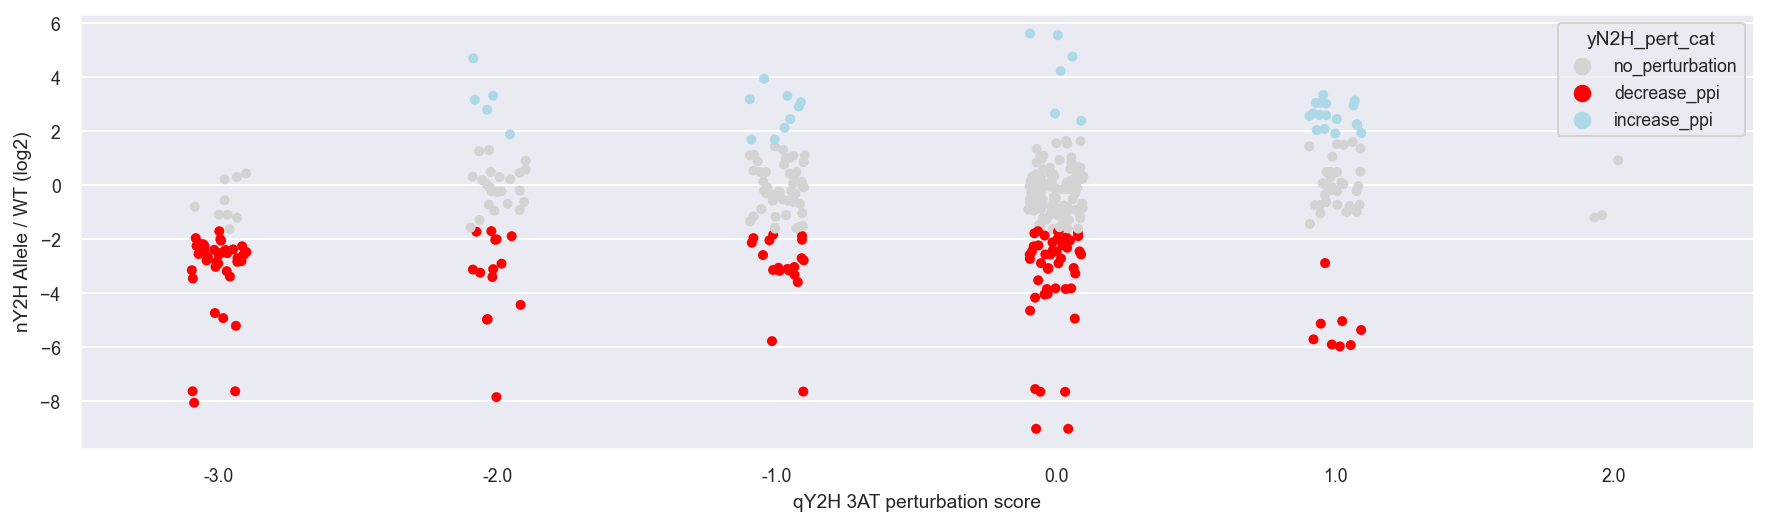

In [159]:
plt.figure(figsize=(15,4))
sns.stripplot(data=big_table[big_table.yN2H_WT_pos == True], x='q_perturb', y=big_table.yN2H_AWT_r.apply(np.log2), hue='yN2H_pert_cat', palette={'decrease_ppi':'red',
                                                                                                                                                 'increase_ppi':'lightblue',
                                                                                                                                                 'no_perturbation':'lightgray'}
             )
plt.xlabel('qY2H 3AT perturbation score')
plt.ylabel('nY2H Allele / WT (log2)')
plt.show()

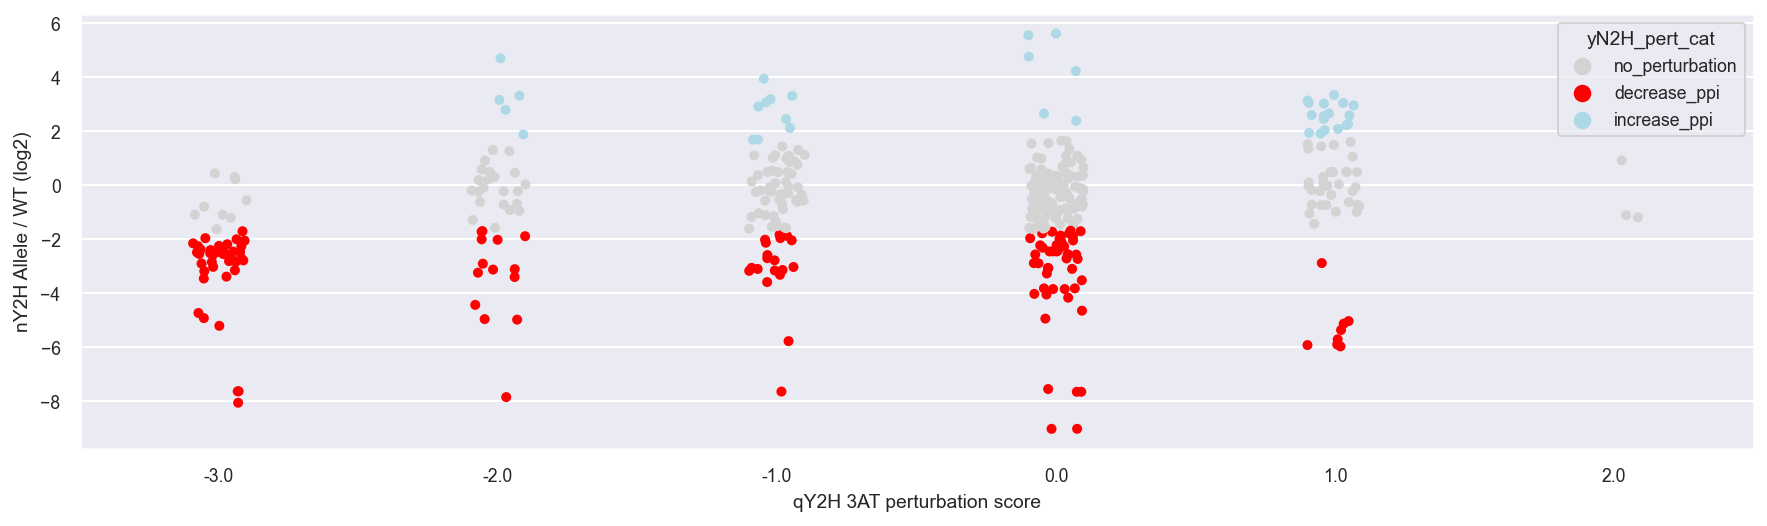

In [160]:
plt.figure(figsize=(15,4))
sns.stripplot(data=big_table[big_table.yN2H_WT_pos == True], x='q_perturb', y=big_table.yN2H_AWT_r.apply(np.log2), hue='yN2H_pert_cat', palette={'decrease_ppi':'red',
                                                                                                                                                 'increase_ppi':'lightblue',
                                                                                                                                                 'no_perturbation':'lightgray'}
             )
plt.xlabel('qY2H 3AT perturbation score')
plt.ylabel('nY2H Allele / WT (log2)')
plt.show()

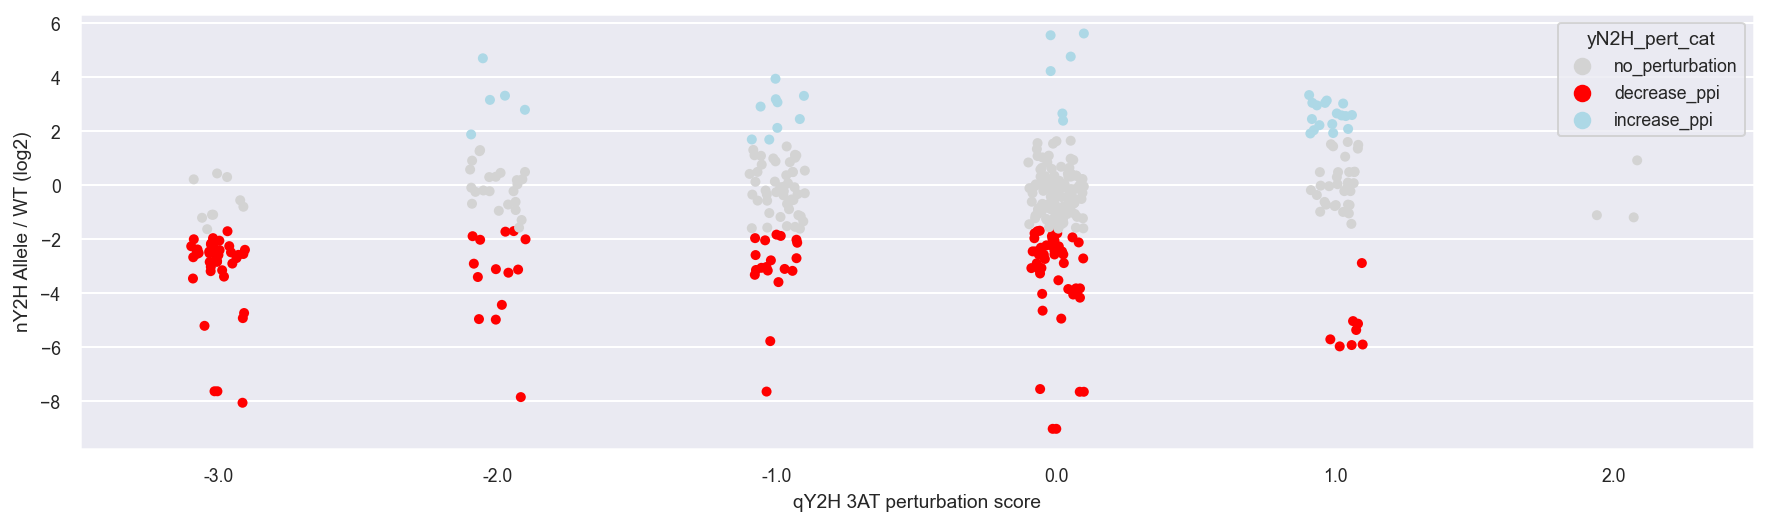

In [161]:
plt.figure(figsize=(15,4))
sns.stripplot(data=big_table[big_table.yN2H_WT_pos == True], x='q_perturb', y=big_table.yN2H_AWT_r.apply(np.log2), hue='yN2H_pert_cat', palette={'decrease_ppi':'red',
                                                                                                                                                 'increase_ppi':'lightblue',
                                                                                                                                                 'no_perturbation':'lightgray'}
             )
plt.xlabel('qY2H 3AT perturbation score')
plt.ylabel('nY2H Allele / WT (log2)')
plt.show()

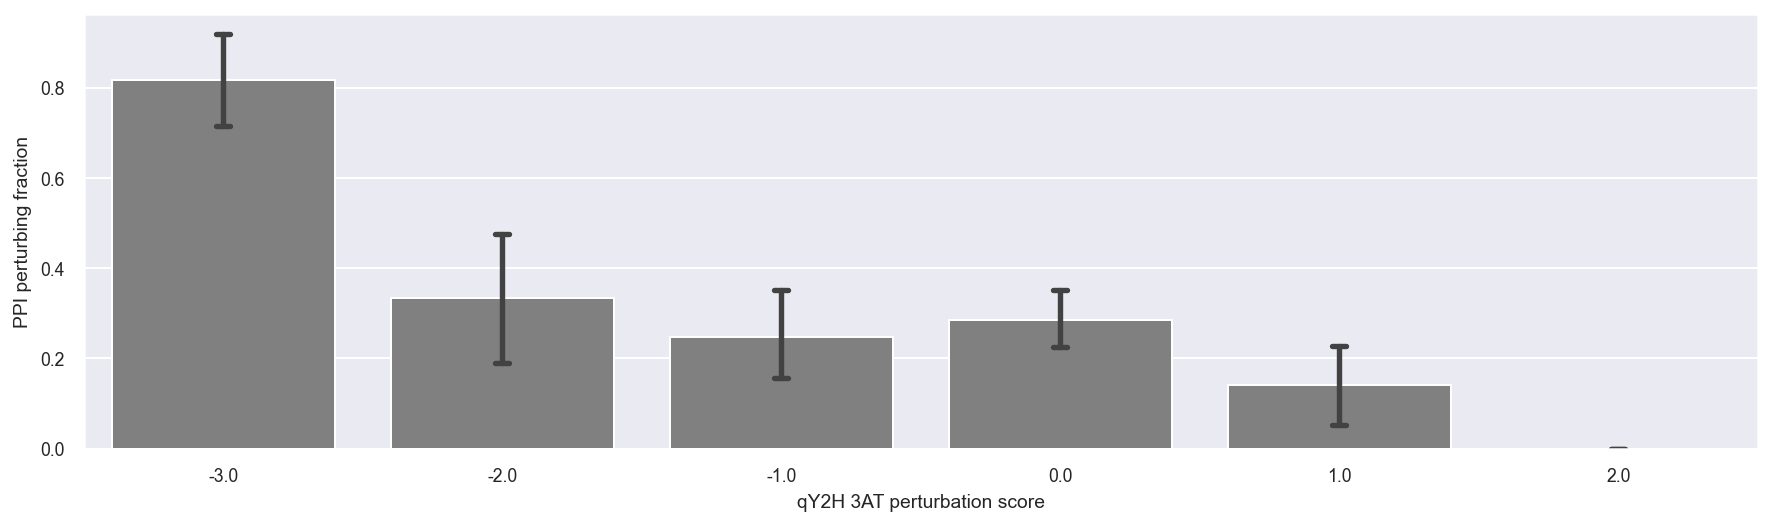

In [162]:
plt.figure(figsize=(15,4))
sns.barplot(data=big_table[big_table.yN2H_WT_pos == True], 
            x='q_perturb', 
            y=big_table[big_table.yN2H_WT_pos == True].yN2H_pert_cat.apply(lambda x: np.nan if x != x else 1 if x == 'decrease_ppi' else 0),
            color='gray', capsize=0.05
           )
plt.xlabel('qY2H 3AT perturbation score')
plt.ylabel('PPI perturbing fraction')
plt.show()

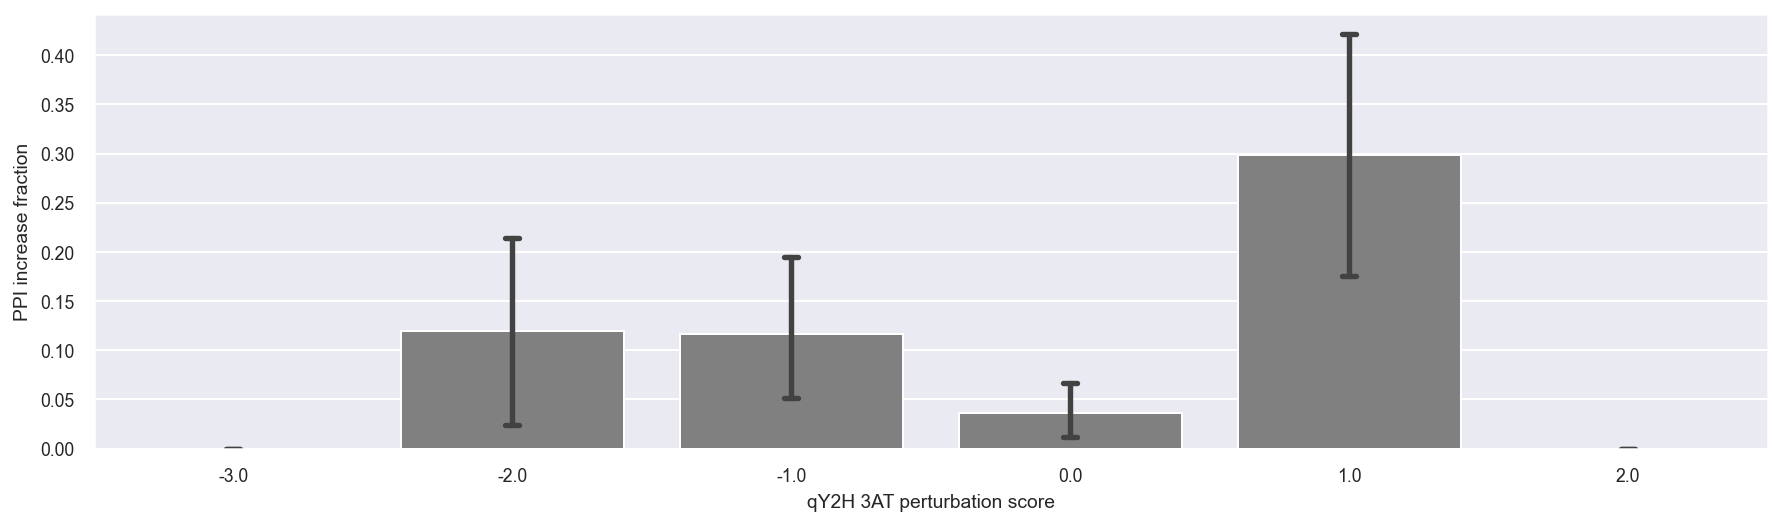

In [163]:
plt.figure(figsize=(15,4))
sns.barplot(data=big_table[big_table.yN2H_WT_pos == True], 
            x='q_perturb', 
            y=big_table[big_table.yN2H_WT_pos == True].yN2H_pert_cat.apply(lambda x: np.nan if x != x else 1 if x == 'increase_ppi' else 0),
            color='gray', capsize=0.05
           )
plt.xlabel('qY2H 3AT perturbation score')
plt.ylabel('PPI increase fraction')
plt.show()

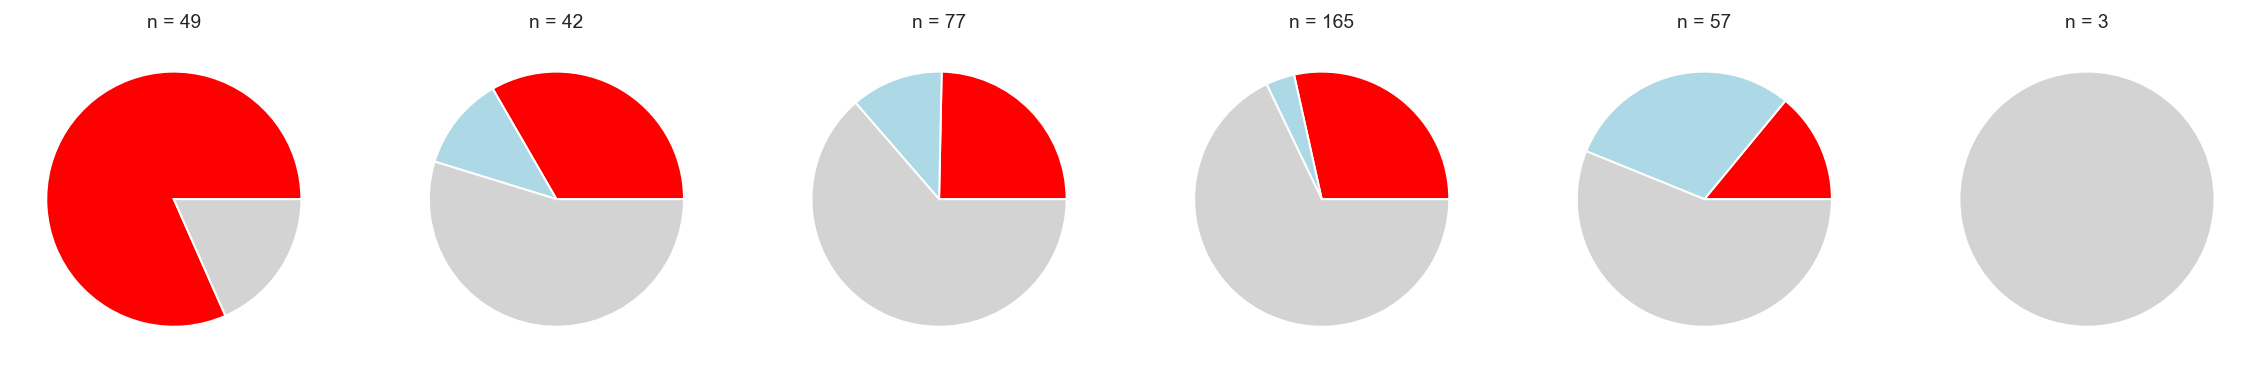

In [164]:
fig, (ax1,ax2,ax3,ax4,ax5,ax6) = plt.subplots(1, 6,figsize=(20, 20))
for ax,qpert in zip([ax1,ax2,ax3,ax4,ax5,ax6],[-3,-2,-1,0,1,2]):
    ax.set_title(f'n = {len(big_table[(big_table.yN2H_WT_pos == True)&(big_table.q_perturb == qpert)])}')
    if qpert == -3:
        colors = ['red','lightgray']
    elif qpert == 2:
        colors = ['lightgray']
    else:
        colors = ['red','lightblue','lightgray']
        
    big_table[(big_table.yN2H_WT_pos == True)&(big_table.q_perturb == qpert)].yN2H_pert_cat.value_counts().sort_index().plot.pie(ax=ax, colors=colors,labeldistance=None)
    ax.set_ylabel('')
    
plt.show()

## Gene level analysis

In [165]:
big_table.head()

,ad_orf_id,db_orf_id,orf_pair,db_mut_id,assay_id,LW,LWH1,LWH10,LWH25,LWA,LWAH1,sum_score,n_condition,allele_score_norm,wt_score_norm,valid,nt_change,aa_change,clinical_significance,db_symbol,ad_symbol,NLR,avg_NLR_mN2H,avg_NLR_yN2H,d_nanoY2H,d_mN2H,d_yN2H,d_ade,d_his1,d_his10,d_his25,q3AT,WT_q3AT,n_media_q3AT,n_syst,lit_bm,lit_bs,perturb_class,q_perturb,yN2H_AWT_r,yN2H_WT_pos,yN2H_pert_cat,mN2H_AWT_r,mN2H_WT_pos,mN2H_pert_cat,nY2H_AWT_r,nY2H_WT_pos,nY2H_pert_cat,pdest_awr,pdest_zscore,pdest_zcat
0,54326.0,7323.0,"(7323.0, 54326.0)",0.0,1.0,"[4.0, 4.0, True]","[3.0, 0.0, 1]","[2.0, 0.0, 1]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]",2.0,5.0,0.4,0.4,True,WT,WT,WT,PMP22,EDA,-0.079680,1.370158,NaN,False,False,True,False,True,True,False,2.0,2.0,3.0,1.0,False,False,NP,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,100000046.0,7323.0,"(7323.0, 100000046.0)",0.0,6.0,"[3.0, 4.0, True]","[3.0, 0.0, 1]","[3.0, 0.0, 1]","[3.0, 0.0, 1]","[2.0, 0.0, 1]","[3.0, 0.0, 1]",5.0,5.0,1.0,1.0,True,WT,WT,WT,PMP22,CLDN5,0.242321,NaN,NaN,False,False,False,True,True,True,True,3.0,3.0,3.0,1.0,False,False,NP,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,14338.0,7323.0,"(7323.0, 14338.0)",0.0,6.0,"[3.0, 4.0, True]","[3.0, 0.0, 1]","[3.0, 0.0, 1]","[2.0, 0.0, 1]","[nan, 0.0, nan]","[nan, 0.0, nan]",3.0,3.0,1.0,1.0,True,WT,WT,WT,PMP22,TMEM14B,2.110138,NaN,0.424527,True,False,False,False,True,True,True,3.0,3.0,3.0,1.0,False,False,NP,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,53702.0,7323.0,"(7323.0, 53702.0)",0.0,6.0,"[3.0, 4.0, True]","[2.0, 0.0, 1]","[1.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]",1.0,5.0,0.2,0.2,True,WT,WT,WT,PMP22,TMEM30B,0.406018,567.770763,0.617488,False,True,True,False,True,False,False,1.0,1.0,3.0,2.0,False,False,NP,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,13628.0,7323.0,"(7323.0, 13628.0)",0.0,2.0,"[3.75, 4.0, True]","[3.0, 0.0, 1]","[4.0, 0.0, 1]","[2.0, 0.0, 1]","[3.0, 0.0, 1]","[3.0, 0.0, 1]",5.0,5.0,1.0,1.0,True,WT,WT,WT,PMP22,KLRC1,4.198374,193.831089,NaN,True,True,True,True,True,True,True,3.0,3.0,3.0,4.0,False,False,NP,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [342]:
big_table[~big_table.yN2H_pert_cat.isnull()]

,ad_orf_id,db_orf_id,orf_pair,db_mut_id,assay_id,LW,LWH1,LWH10,LWH25,LWA,LWAH1,sum_score,n_condition,allele_score_norm,wt_score_norm,valid,nt_change,aa_change,clinical_significance,db_symbol,ad_symbol,NLR,avg_NLR_mN2H,avg_NLR_yN2H,d_nanoY2H,d_mN2H,d_yN2H,d_ade,d_his1,d_his10,d_his25,q3AT,WT_q3AT,n_media_q3AT,n_syst,lit_bm,lit_bs,perturb_class,q_perturb,yN2H_AWT_r,yN2H_WT_pos,yN2H_pert_cat,mN2H_AWT_r,mN2H_WT_pos,mN2H_pert_cat,nY2H_AWT_r,nY2H_WT_pos,nY2H_pert_cat,pdest_awr,pdest_zscore,pdest_zcat
1044,7233.0,7652.0,"(7652.0, 7233.0)",1790.0,1.0,"[4.0, 3.0, True]","[2.0, 0.0, 1]","[2.0, 0.0, 1]","[2.0, 0.0, 1]","[0.0, 0.0, 0]","[0.0, 0.0, 0]",3.0,5.0,0.6,0.6,True,36G>C,Glu12Asp,VUS,STXBP1,STX5,1.439691,233.281036,1.393690,False,True,True,False,True,True,True,3.0,3.0,3.0,2.0,False,False,NP,0.0,2.469760,False,not_detected,9.707993,False,not_detected,4.356158,False,not_detected,0.700017,-0.979699,0.0
1045,2615.0,7652.0,"(7652.0, 2615.0)",1790.0,2.0,"[3.75, 3.0, True]","[3.0, 0.0, 1]","[3.0, 0.0, 1]","[2.0, 0.0, 1]","[3.0, 0.0, 1]","[3.0, 0.0, 1]",5.0,5.0,1.0,1.0,True,36G>C,Glu12Asp,VUS,STXBP1,STX19,2.266702,352.718637,4.028909,True,True,True,True,True,True,True,3.0,3.0,3.0,4.0,False,False,NP,0.0,7.139636,False,not_detected,14.678389,False,not_detected,6.858495,False,not_detected,0.700017,-0.979699,0.0
1046,199.0,7652.0,"(7652.0, 199.0)",1790.0,6.0,"[3.0, 3.0, True]","[3.0, 0.0, 1]","[3.0, 0.0, 1]","[2.0, 0.0, 1]","[1.0, 0.0, 0]","[2.0, 0.0, 1]",4.0,5.0,0.8,1.0,True,36G>C,Glu12Asp,VUS,STXBP1,SYTL4,NaN,246.554405,2.679903,NaN,True,True,True,True,True,True,3.0,3.0,3.0,3.0,False,False,NP,0.0,4.749060,False,not_detected,10.260364,False,not_detected,NaN,NaN,NaN,0.700017,-0.979699,0.0
1047,14387.0,7652.0,"(7652.0, 14387.0)",1790.0,6.0,"[3.0, 3.0, True]","[2.0, 0.0, 1]","[2.0, 0.0, 1]","[2.0, 0.0, 1]","[2.0, 0.0, 1]","[2.0, 0.0, 1]",5.0,5.0,1.0,1.0,True,36G>C,Glu12Asp,VUS,STXBP1,CENPP,4.771186,66.988983,1.328603,True,True,True,True,True,True,True,3.0,3.0,3.0,4.0,False,False,NP,0.0,2.354419,False,not_detected,2.787747,False,not_detected,14.436462,False,not_detected,0.700017,-0.979699,0.0
1050,7233.0,7652.0,"(7652.0, 7233.0)",1794.0,1.0,"[4.0, 3.0, True]","[3.0, 0.0, 1]","[2.0, 0.0, 1]","[2.0, 0.0, 1]","[0.0, 0.0, 0]","[0.0, 0.0, 0]",3.0,5.0,0.6,0.6,True,281C>T,Pro94Leu,Benign,STXBP1,STX5,0.414663,89.736954,0.987504,False,True,True,False,True,True,True,3.0,3.0,3.0,2.0,False,False,NP,0.0,1.749958,False,not_detected,3.734404,False,not_detected,1.254670,False,not_detected,0.981137,-0.177635,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5323,7982.0,7982.0,"(7982.0, 7982.0)",202802.0,1.0,"[4.0, 4.0, True]","[3.0, 0.0, 1]","[4.0, 0.0, 1]","[3.0, 0.0, 1]","[3.0, 0.0, 1]","[4.0, 0.0, 1]",5.0,5.0,1.0,1.0,True,419G>A,Gly140Asp,Pathogenic,HPRT1,HPRT1,6.902846,NaN,2.713321,True,False,False,True,True,True,True,3.0,3.0,3.0,2.0,False,False,NP,0.0,0.367619,True,no_perturbation,NaN,NaN,NaN,0.958383,True,no_perturbation,NaN,NaN,NaN
5633,6446.0,54230.0,"(54230.0, 6446.0)",218818.0,6.0,"[3.0, 3.0, True]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]",0.0,5.0,0.0,1.0,True,413C>G,Thr138Arg,Pathogenic,MIP,ERGIC3,-0.446534,NaN,1.270767,False,False,False,False,False,False,False,0.0,3.0,3.0,0.0,False,False,P,-3.0,1.144955,False,not_detected,NaN,NaN,NaN,-2.695388,False,not_detected,NaN,NaN,NaN
5635,2012.0,54230.0,"(54230.0, 2012.0)",218818.0,6.0,"[3.0, 3.0, True]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]",0.0,5.0,0.0,0.2,True,413C>G,Thr138Arg,Pathogenic,MIP,LHFPL5,-1.028407,NaN,12.163851,False,False,False,False,False,False,False,0.0,1.0,3.0,0.0,False,False,P,-1.0,10.959573,False,not_detected,NaN,NaN,NaN,-6.207725,False,not_detected,NaN,NaN,NaN
5636,13219.0,54230.0,"(54230.0, 13219.0)",218818.0,6.0,"[3.0, 3.0, True]","[0.0, 0.0, 0]","[0.

In [249]:
#aa_change_d = dict(zip(zip(big_table.db_orf_id, big_table.db_mut_id),big_table.aa_change))
#cs_d = dict(zip(zip(big_table.db_symbol, big_table.aa_change),big_table.clinical_significance))

In [250]:
col = ['ad_orf_id', 'db_orf_id', 'orf_pair', 'db_mut_id', 'assay_id', 'LW',
       'LWH1', 'LWH10', 'LWH25', 'LWA', 'LWAH1', 'sum_score', 'n_condition',
       'allele_score_norm', 'wt_score_norm', 'valid', 'nt_change', 'aa_change',
       'clinical_significance', 'db_symbol', 'ad_symbol', 'NLR',
       'avg_NLR_mN2H', 'avg_NLR_yN2H', 'd_nanoY2H', 'd_mN2H', 'd_yN2H',
       'd_ade', 'd_his1', 'd_his10', 'd_his25', 'q3AT', 'WT_q3AT',
       'n_media_q3AT', 'n_syst', 'lit_bm', 'lit_bs', 'perturb_class',
       'q_perturb', 'yN2H_AWT_r', 'yN2H_WT_pos', 'yN2H_pert_cat', 'mN2H_AWT_r',
       'mN2H_WT_pos', 'mN2H_pert_cat', 'nY2H_AWT_r', 'nY2H_WT_pos',
       'nY2H_pert_cat', 'pdest_awr', 'pdest_zscore', 'pdest_zcat']

In [251]:
gene_level_d = dict()

for i, row in big_table.iterrows():
    ad_orf_id = row.ad_orf_id
    db_orf_id = row.db_orf_id
    db_mut_id = row.db_mut_id
    q_perturb = row.q_perturb
    q3AT = row.q3AT
    WT_q3AT = row.WT_q3AT
    yN2H_pert_cat = row.yN2H_pert_cat
    mN2H_pert_cat = row.mN2H_pert_cat
    pdest_zscore = row.pdest_zscore
    pdest_zcat = row.pdest_zcat

    if (db_orf_id, db_mut_id) not in gene_level_d:
        gene_level_d[db_orf_id, db_mut_id] = {'qY2H':{(ad_orf_id,q3AT,WT_q3AT,q3AT)},
                                              'yN2H':{(ad_orf_id,yN2H_pert_cat)},
                                              'mN2H':{(ad_orf_id,mN2H_pert_cat)},
                                              'pdest_zscore':pdest_zscore,
                                              'pdest_zcat':pdest_zcat
                                             }
    else:
        gene_level_d[db_orf_id, db_mut_id]['qY2H'].add((ad_orf_id,q3AT,WT_q3AT,q3AT))
        gene_level_d[db_orf_id, db_mut_id]['yN2H'].add((ad_orf_id,yN2H_pert_cat))
        gene_level_d[db_orf_id, db_mut_id]['mN2H'].add((ad_orf_id,mN2H_pert_cat))
        if pdest_zscore == pdest_zscore:
            gene_level_d[db_orf_id, db_mut_id]['pdest_zscore'] = pdest_zscore
            gene_level_d[db_orf_id, db_mut_id]['pdest_zcat'] = pdest_zcat



In [252]:
gene_level_df = pd.DataFrame(gene_level_d).T
gene_level_df.reset_index(inplace=True)
gene_level_df.rename(columns={'level_0':'db_orf_id','level_1':'db_mut_id'}, inplace=True)
gene_level_df = gene_level_df[gene_level_df.db_mut_id != 0].copy()

gene_level_df['yN2H'] = gene_level_df.yN2H.apply(lambda x: {e for e in x if e[-1]==e[-1] and e[-1]!='not_detected'})
gene_level_df['mN2H'] = gene_level_df.mN2H.apply(lambda x: {e for e in x if e[-1]==e[-1] and e[-1]!='not_detected'})

gene_level_df['qY2H_degree'] = gene_level_df.qY2H.apply(len)
gene_level_df['qmN2H_degree'] = gene_level_df.mN2H.apply(len)
gene_level_df['qyN2H_degree'] = gene_level_df.yN2H.apply(len)

def qY2H_node_call(score):
    qy2h = [e[1] for e in score]
    if sum(qy2h) == 0:
        res = 'Node Removal'
    elif 0 in qy2h:
        res = 'Edgetic'
    else:
        res = 'PPI WT like'
        
    return res

gene_level_df['qY2H_node_call'] = gene_level_df.qY2H.apply(qY2H_node_call)

gene_level_df.head()

,db_orf_id,db_mut_id,qY2H,yN2H,mN2H,pdest_zscore,pdest_zcat,qY2H_degree,qmN2H_degree,qyN2H_degree,qY2H_node_call
17,70497.0,3780.0,"{(100067219.0, 0.0, 1.0, 0.0), (54668.0, 0.0, ...",{},{},1.410362,1.0,7,0,0,Node Removal
18,70497.0,3782.0,"{(100067219.0, 0.0, 1.0, 0.0), (54668.0, 0.0, ...",{},{},-0.31451,0.0,7,0,0,Node Removal
19,70497.0,3785.0,"{(100067219.0, 0.0, 1.0, 0.0), (54668.0, 0.0, ...",{},{},0.152722,0.0,7,0,0,Node Removal
20,70497.0,3786.0,"{(54668.0, 0.0, 2.0, 0.0), (13662.0, 3.0, 3.0,...",{},{},-0.888698,0.0,7,0,0,Edgetic
21,70497.0,3789.0,"{(100067219.0, 0.0, 1.0, 0.0), (54668.0, 0.0, ...",{},{},-0.861603,0.0,7,0,0,Node Removal


Text(0.5, 0, '')

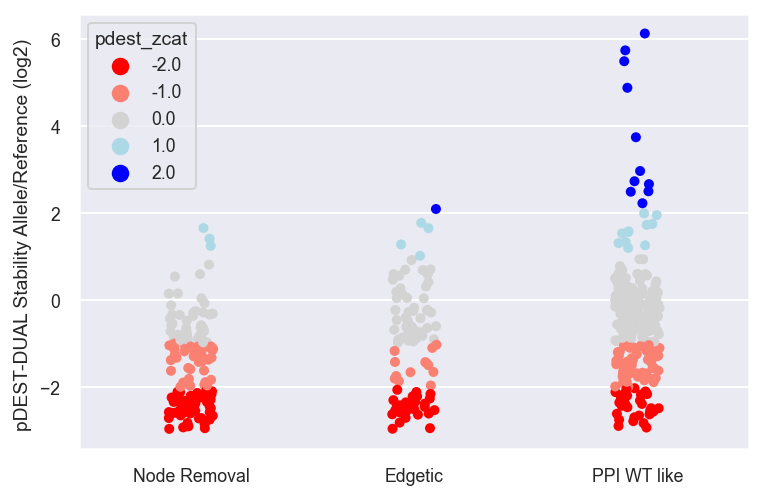

In [253]:
sns.stripplot(data=gene_level_df, x='qY2H_node_call', y='pdest_zscore', hue='pdest_zcat',palette={-2:'red',
                                                                                                                                             -1:'salmon',
                                                                                                                                             0:'lightgray',
                                                                                                                                             1:'lightblue',
                                                                                                                                             2:'blue'})
plt.ylabel('pDEST-DUAL Stability Allele/Reference (log2) ')
plt.xlabel('')

<AxesSubplot:xlabel='qY2H_node_call', ylabel='pdest_zscore'>

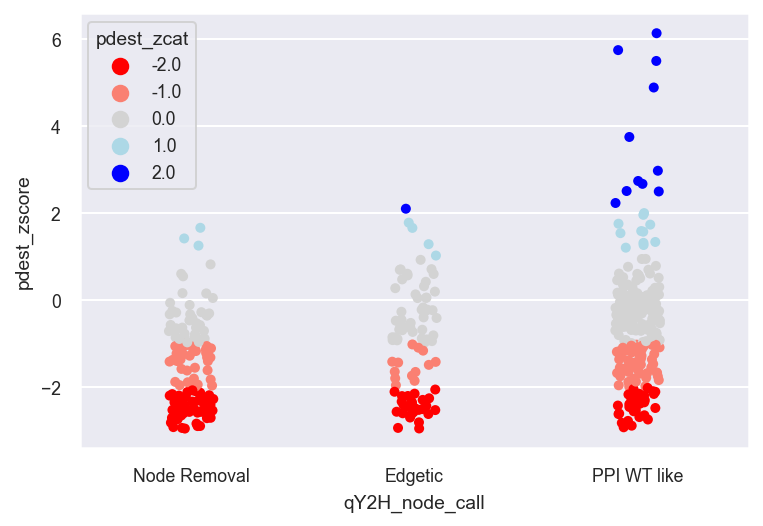

In [254]:
sns.stripplot(data=gene_level_df, x='qY2H_node_call', y='pdest_zscore', hue='pdest_zcat',palette={-2:'red',
                                                                                                                                             -1:'salmon',
                                                                                                                                             0:'lightgray',
                                                                                                                                             1:'lightblue',
                                                                                                                                             2:'blue'})

Text(0.5, 0, '')

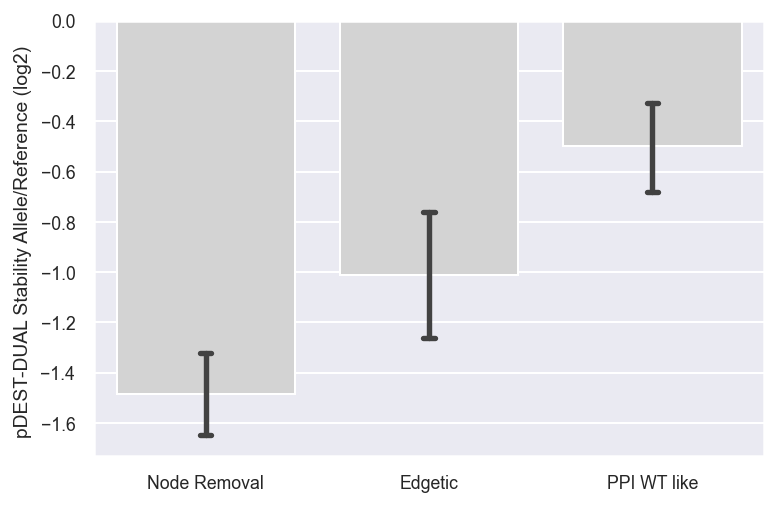

In [255]:
sns.barplot(data=gene_level_df, x='qY2H_node_call', y='pdest_zscore', color='lightgray',  capsize=0.05)

plt.ylabel('pDEST-DUAL Stability Allele/Reference (log2) ')
plt.xlabel('')

<AxesSubplot:xlabel='qY2H_node_call', ylabel='pdest_zscore'>

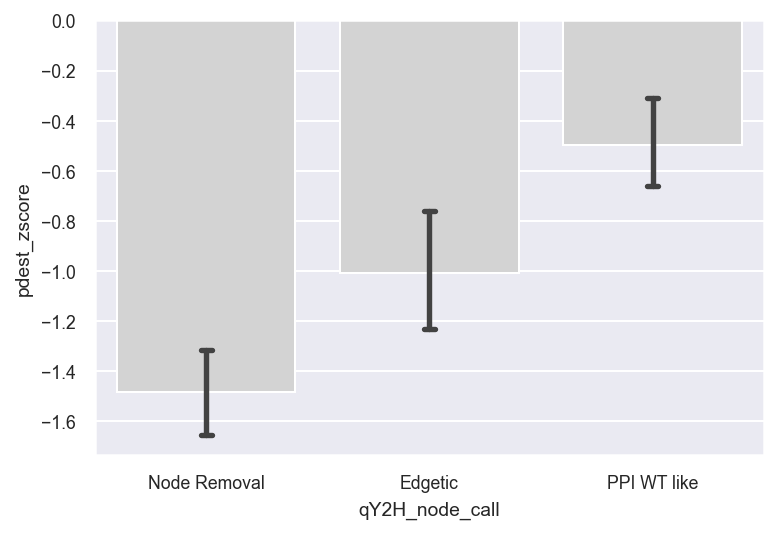

In [256]:
sns.barplot(data=gene_level_df, x='qY2H_node_call', y='pdest_zscore', color='lightgray',  capsize=0.05)

<AxesSubplot:xlabel='qY2H_node_call', ylabel='pdest_zscore'>

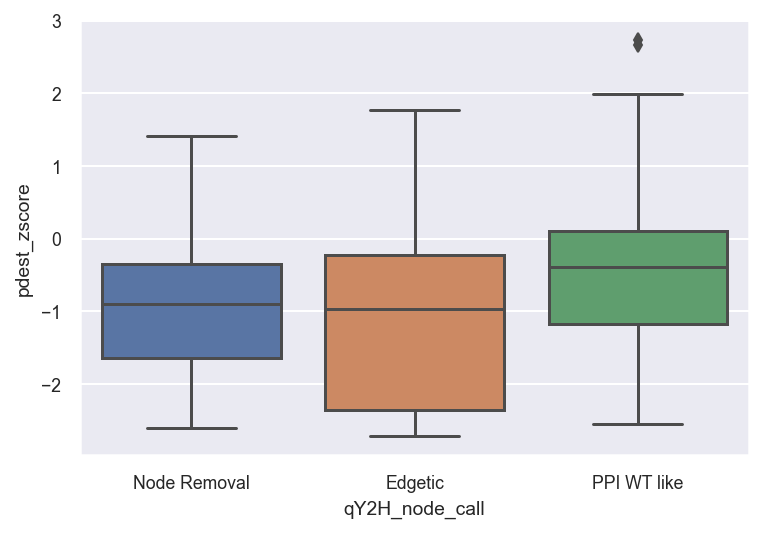

In [257]:
sns.boxplot(data=gene_level_df[gene_level_df.qY2H_degree > 3], x='qY2H_node_call', y='pdest_zscore')

<AxesSubplot:xlabel='qY2H_node_call', ylabel='pdest_zscore'>

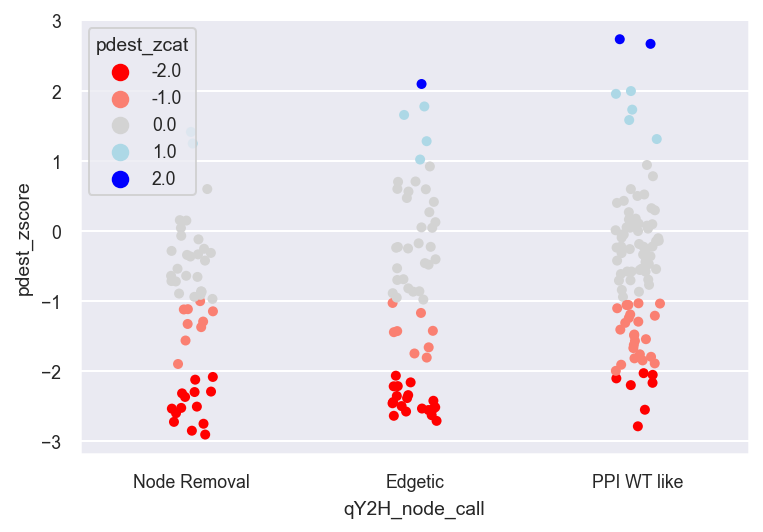

In [258]:
sns.stripplot(data=gene_level_df[gene_level_df.qY2H_degree > 2], x='qY2H_node_call', y='pdest_zscore',hue='pdest_zcat',palette={-2:'red',
                                                                                                                                 -1:'salmon',
                                                                                                                                 0:'lightgray',
                                                                                                                                 1:'lightblue',
                                                                                                                                 2:'blue'})

<AxesSubplot:xlabel='qY2H_node_call', ylabel='pdest_zscore'>

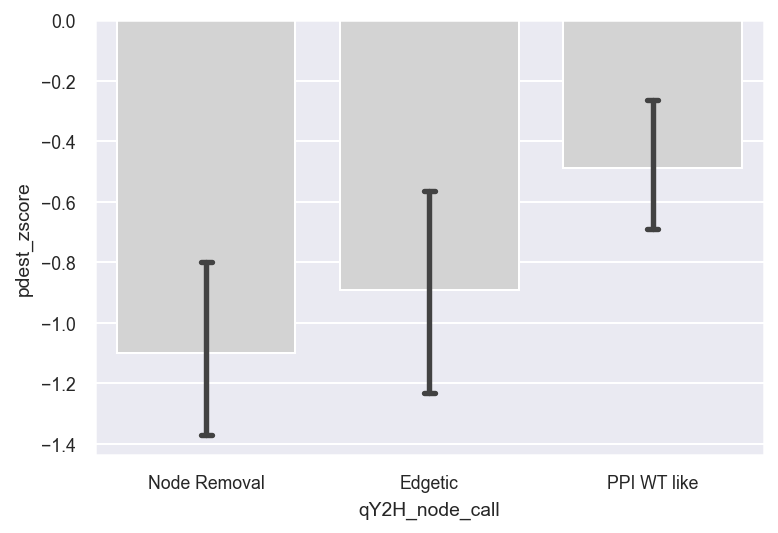

In [259]:
sns.barplot(data=gene_level_df[gene_level_df.qY2H_degree > 2], x='qY2H_node_call', y='pdest_zscore', color='lightgray',  capsize=0.05)

In [260]:
orf_mapping = GetOrfMapping()

orf_to_symbol = dict(zip(orf_mapping.orf_id, orf_mapping.symbol))

In [262]:
cs_d

{('PMP22', 'WT'): 'WT',
 ('TTPA', 'WT'): 'WT',
 ('TPM1', 'WT'): 'WT',
 ('TH', 'WT'): 'WT',
 ('MVK', 'WT'): 'WT',
 ('STXBP1', 'WT'): 'WT',
 ('KCNJ2', 'WT'): 'WT',
 ('MLH1', 'WT'): 'WT',
 ('PKP2', 'WT'): 'WT',
 ('AGXT', 'WT'): 'WT',
 ('LITAF', 'WT'): 'WT',
 ('AIPL1', 'WT'): 'WT',
 ('PYGL', 'WT'): 'WT',
 ('ACSF3', 'WT'): 'WT',
 ('TAT', 'WT'): 'WT',
 ('UBQLN2', 'WT'): 'WT',
 ('EMD', 'WT'): 'WT',
 ('AGXT', 'Pro10Ala'): 'VUS',
 ('AGXT', 'Pro11His'): 'VUS',
 ('AGXT', 'Lys12Arg'): 'VUS',
 ('AGXT', 'Asn22Ser'): 'Conflicting',
 ('AGXT', 'Arg36Cys'): 'Pathogenic',
 ('AGXT', 'Gly41Arg'): 'Pathogenic',
 ('AGXT', 'Gly41Glu'): 'Pathogenic',
 ('AGXT', 'Met49Leu'): 'VUS',
 ('AGXT', 'Gly82Arg'): 'Pathogenic',
 ('AGXT', 'Ala85Asp'): 'Pathogenic',
 ('AGXT', 'Arg111Gln'): 'Pathogenic',
 ('AGXT', 'Gly116Arg'): 'Pathogenic',
 ('AGXT', 'Arg118Cys'): 'VUS',
 ('AGXT', 'Asp129His'): 'VUS',
 ('AGXT', 'Phe152Ile'): 'Pathogenic',
 ('AGXT', 'Gly161Ser'): 'Pathogenic',
 ('AGXT', 'Gly161Arg'): 'Pathogenic',
 ('AGXT', 

In [281]:
gene_level_df['symbol'] = gene_level_df.db_orf_id.map(orf_to_symbol)
gene_level_df['qY2H_node_call_int'] = gene_level_df.qY2H_node_call.map({'Node Removal':5, 'Edgetic':4, 'PPI WT like':3})
#gene_level_df['pdest_zscore_v2'] = gene_level_df.qY2H_node_call.map({'node_removal':-2, 'edgetic':-1, 'qwt':0})
gene_level_df['aa_change'] = [aa_change_d[o,m] for o,m in zip(gene_level_df.db_orf_id, gene_level_df.db_mut_id)]

gene_level_df['symbol_aa_change'] = [f'{s} {aa}' for s,aa in zip(gene_level_df.symbol, gene_level_df.aa_change)]

gene_level_df.head()

,db_orf_id,db_mut_id,qY2H,yN2H,mN2H,pdest_zscore,pdest_zcat,qY2H_degree,qmN2H_degree,qyN2H_degree,qY2H_node_call,symbol,qY2H_node_call_int,aa_change,symbol_aa_change
17,70497.0,3780.0,"{(100067219.0, 0.0, 1.0, 0.0), (54668.0, 0.0, ...",{},{},1.410362,1.0,7,0,0,Node Removal,AGXT,5,Pro10Ala,AGXT Pro10Ala
18,70497.0,3782.0,"{(100067219.0, 0.0, 1.0, 0.0), (54668.0, 0.0, ...",{},{},-0.31451,0.0,7,0,0,Node Removal,AGXT,5,Pro11His,AGXT Pro11His
19,70497.0,3785.0,"{(100067219.0, 0.0, 1.0, 0.0), (54668.0, 0.0, ...",{},{},0.152722,0.0,7,0,0,Node Removal,AGXT,5,Lys12Arg,AGXT Lys12Arg
20,70497.0,3786.0,"{(54668.0, 0.0, 2.0, 0.0), (13662.0, 3.0, 3.0,...",{},{},-0.888698,0.0,7,0,0,Edgetic,AGXT,4,Asn22Ser,AGXT Asn22Ser
21,70497.0,3789.0,"{(100067219.0, 0.0, 1.0, 0.0), (54668.0, 0.0, ...",{},{},-0.861603,0.0,7,0,0,Node Removal,AGXT,5,Arg36Cys,AGXT Arg36Cys


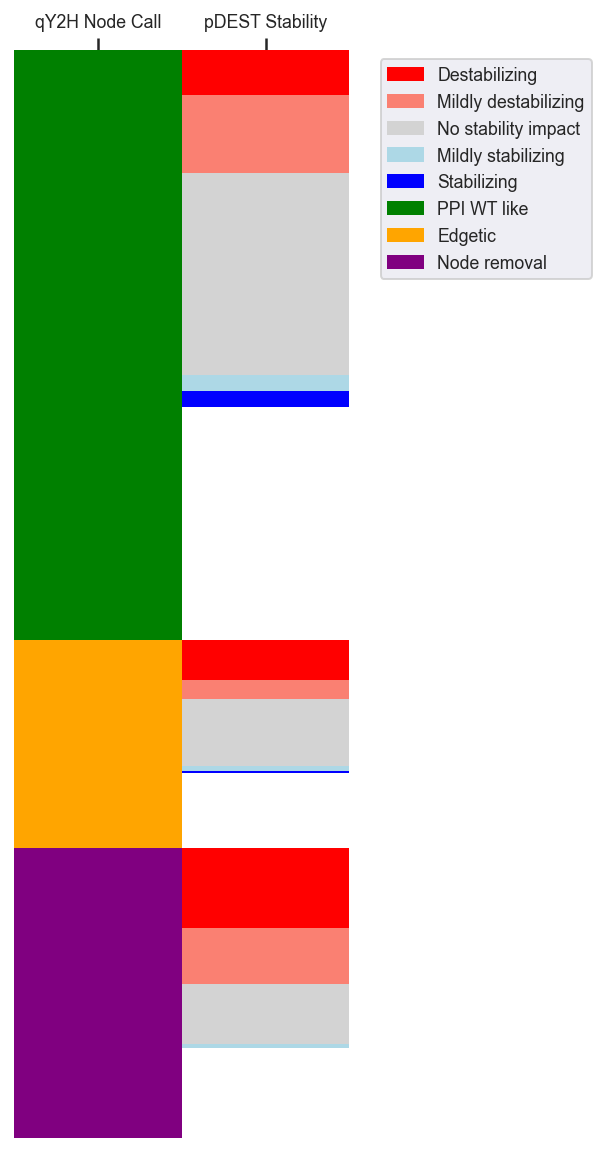

In [282]:
from matplotlib.colors import LinearSegmentedColormap

col = ['aa_change', 'qY2H_node_call_int','pdest_zcat']
df = gene_level_df[col].set_index('aa_change')

df.sort_values(by=['qY2H_node_call_int','pdest_zcat'], inplace=True)

df['qY2H Node Call'] =  df.qY2H_node_call_int.astype(float)
df['pDEST Stability'] =  df.pdest_zcat.astype(float)

df.drop(columns=['qY2H_node_call_int','pdest_zcat'], inplace=True)


plt.figure(figsize=(3,10))
myColors = ('red','salmon','lightgray','lightblue','blue','green','orange','purple')
cmap = LinearSegmentedColormap.from_list('Custom', myColors, len(myColors))
cmap.set_bad("white") 
ax = sns.heatmap(data=df, cmap=cmap, cbar=False, yticklabels=False)

#colorbar = ax.collections[0].colorbar
#colorbar.set_ticks([-2,-1,0,1,2,3,4,5])
#colorbar.set_ticklabels(['Destabilizing','Mildly destabilizing', 'No stability impact', 'Mildly stabilizing', 'Stabilizing', 'PPI WT like', 'Edgetic', 'Node removal'])

ax.xaxis.tick_top()

plt.ylabel('')

import matplotlib.patches as mpatches
red_patch = mpatches.Patch(color='red', label='The red data')
blue_patch = mpatches.Patch(color='blue', label='The blue data')

impacts = ['Destabilizing','Mildly destabilizing', 'No stability impact', 'Mildly stabilizing', 'Stabilizing', 'PPI WT like', 'Edgetic', 'Node removal']

#plt.legend(handles=[red_patch, blue_patch])

plt.legend(handles=[mpatches.Patch(color=color, label=impact) for color,impact in zip(myColors,impacts)],  bbox_to_anchor=(1.75, 1))

plt.show()



STXBP1


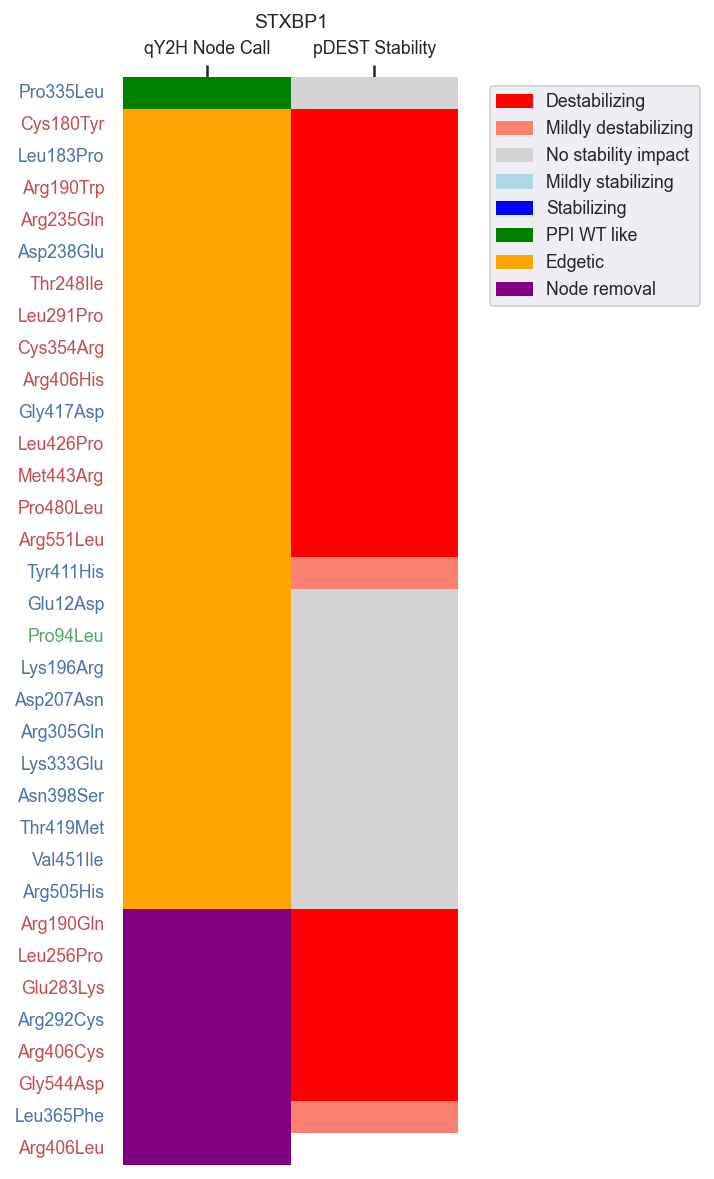

In [283]:
symbol = 'STXBP1'
print(symbol)

from matplotlib.colors import LinearSegmentedColormap

col = ['aa_change', 'qY2H_node_call_int','pdest_zcat']
df = gene_level_df.query(f"symbol == '{symbol}'")[col].set_index('aa_change')

df.sort_values(by=['qY2H_node_call_int','pdest_zcat'], inplace=True)

df['qY2H Node Call'] =  df.qY2H_node_call_int.astype(float).T
df['pDEST Stability'] =  df.pdest_zcat.astype(float).T

df.drop(columns=['qY2H_node_call_int','pdest_zcat'], inplace=True)


plt.figure(figsize=(3,10))
plt.title(f'{symbol}')
myColors = ('red','salmon','lightgray','lightblue','blue','green','orange','purple')
cmap = LinearSegmentedColormap.from_list('Custom', myColors, len(myColors))
cmap.set_bad("white") 
ax = sns.heatmap(data=df, cmap=cmap, cbar=False)

ax.xaxis.tick_top()
plt.ylabel('')

cs_color_d = {'VUS':'b','Pathogenic':'r', 'Conflicting':'b','Benign':'g','WT':'black'}
for tick_label in ax.get_yticklabels():
    aa_change = tick_label.get_text()
    cs = cs_d[(symbol,aa_change)]
    color = cs_color_d[cs] 
    tick_label.set_color(color)

import matplotlib.patches as mpatches
red_patch = mpatches.Patch(color='red', label='The red data')
blue_patch = mpatches.Patch(color='blue', label='The blue data')

impacts = ['Destabilizing','Mildly destabilizing', 'No stability impact', 'Mildly stabilizing', 'Stabilizing', 'PPI WT like', 'Edgetic', 'Node removal']

#plt.legend(handles=[red_patch, blue_patch])

plt.legend(handles=[mpatches.Patch(color=color, label=impact) for color,impact in zip(myColors,impacts)],  bbox_to_anchor=(1.75, 1))

plt.show()


MVK


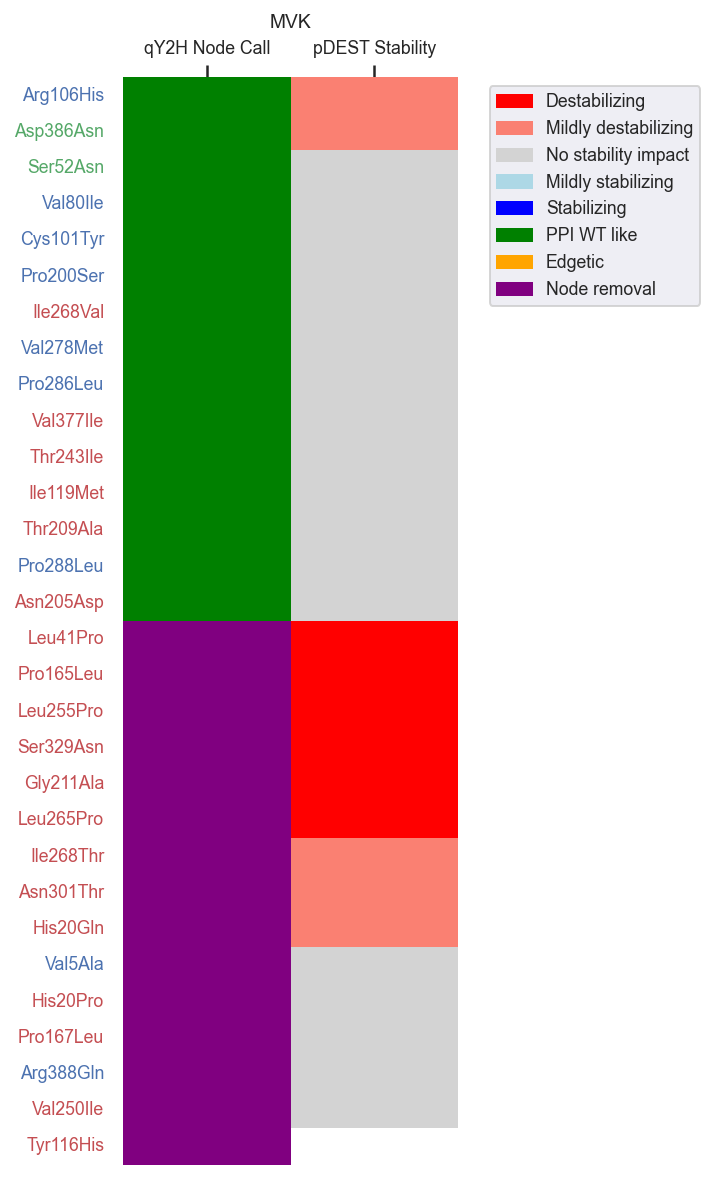

In [284]:
symbol = 'MVK'
print(symbol)

from matplotlib.colors import LinearSegmentedColormap

col = ['aa_change', 'qY2H_node_call_int','pdest_zcat']
df = gene_level_df.query(f"symbol == '{symbol}'")[col].set_index('aa_change')

df.sort_values(by=['qY2H_node_call_int','pdest_zcat'], inplace=True)

df['qY2H Node Call'] =  df.qY2H_node_call_int.astype(float).T
df['pDEST Stability'] =  df.pdest_zcat.astype(float).T

df.drop(columns=['qY2H_node_call_int','pdest_zcat'], inplace=True)


plt.figure(figsize=(3,10))
plt.title(f'{symbol}')
myColors = ('red','salmon','lightgray','lightblue','blue','green','orange','purple')
cmap = LinearSegmentedColormap.from_list('Custom', myColors, len(myColors))
cmap.set_bad("white") 
ax = sns.heatmap(data=df, cmap=cmap, cbar=False)

ax.xaxis.tick_top()
plt.ylabel('')

cs_color_d = {'VUS':'b','Pathogenic':'r', 'Conflicting':'b','Benign':'g','WT':'black'}
for tick_label in ax.get_yticklabels():
    aa_change = tick_label.get_text()
    cs = cs_d[(symbol,aa_change)]
    color = cs_color_d[cs] 
    tick_label.set_color(color)

import matplotlib.patches as mpatches
red_patch = mpatches.Patch(color='red', label='The red data')
blue_patch = mpatches.Patch(color='blue', label='The blue data')

impacts = ['Destabilizing','Mildly destabilizing', 'No stability impact', 'Mildly stabilizing', 'Stabilizing', 'PPI WT like', 'Edgetic', 'Node removal']

#plt.legend(handles=[red_patch, blue_patch])

plt.legend(handles=[mpatches.Patch(color=color, label=impact) for color,impact in zip(myColors,impacts)],  bbox_to_anchor=(1.75, 1))

plt.show()



In [361]:
gene_level_df[gene_level_df.db_orf_id == 281].head()

,db_orf_id,db_mut_id,qY2H,yN2H,mN2H,pdest_zscore,pdest_zcat,qY2H_degree,qmN2H_degree,qyN2H_degree,qY2H_node_call,symbol,qY2H_node_call_int,aa_change,symbol_aa_change
160,281.0,1.0,"{(281.0, 0.0, 1.0, 0.0)}","{(281.0, no_perturbation)}",{},-0.967716,0.0,1,0,1,Node Removal,MVK,5,Val5Ala,MVK Val5Ala
161,281.0,3.0,"{(281.0, 0.0, 1.0, 0.0)}","{(281.0, decrease_ppi)}",{},0.814025,0.0,1,0,1,Node Removal,MVK,5,His20Pro,MVK His20Pro
162,281.0,4.0,"{(281.0, 0.0, 1.0, 0.0)}","{(281.0, decrease_ppi)}",{},-2.827054,-2.0,1,0,1,Node Removal,MVK,5,Leu41Pro,MVK Leu41Pro
163,281.0,5.0,"{(281.0, 1.0, 1.0, 1.0)}","{(281.0, no_perturbation)}",{},0.144154,0.0,1,0,1,PPI WT like,MVK,3,Ser52Asn,MVK Ser52Asn
164,281.0,6.0,"{(281.0, 1.0, 1.0, 1.0)}","{(281.0, no_perturbation)}",{},-0.813608,0.0,1,0,1,PPI WT like,MVK,3,Val80Ile,MVK Val80Ile


In [367]:
gene_level_df.query(f"symbol == '{symbol}'")[col].set_index('aa_change').copy()

,qY2H_node_call_int,yN2H,pdest_zcat
aa_change,,,
Val5Ala,5,"{(281.0, no_perturbation)}",0.0
His20Pro,5,"{(281.0, decrease_ppi)}",0.0
Leu41Pro,5,"{(281.0, decrease_ppi)}",-2.0
Ser52Asn,3,"{(281.0, no_perturbation)}",0.0
Val80Ile,3,"{(281.0, no_perturbation)}",0.0
Cys101Tyr,3,"{(281.0, no_perturbation)}",0.0
Arg106His,3,"{(281.0, no_perturbation)}",-1.0
Tyr116His,5,"{(281.0, decrease_ppi)}",NaN
Pro165Leu,5,"{(281.0, no_perturbation)}",-2.0


MVK


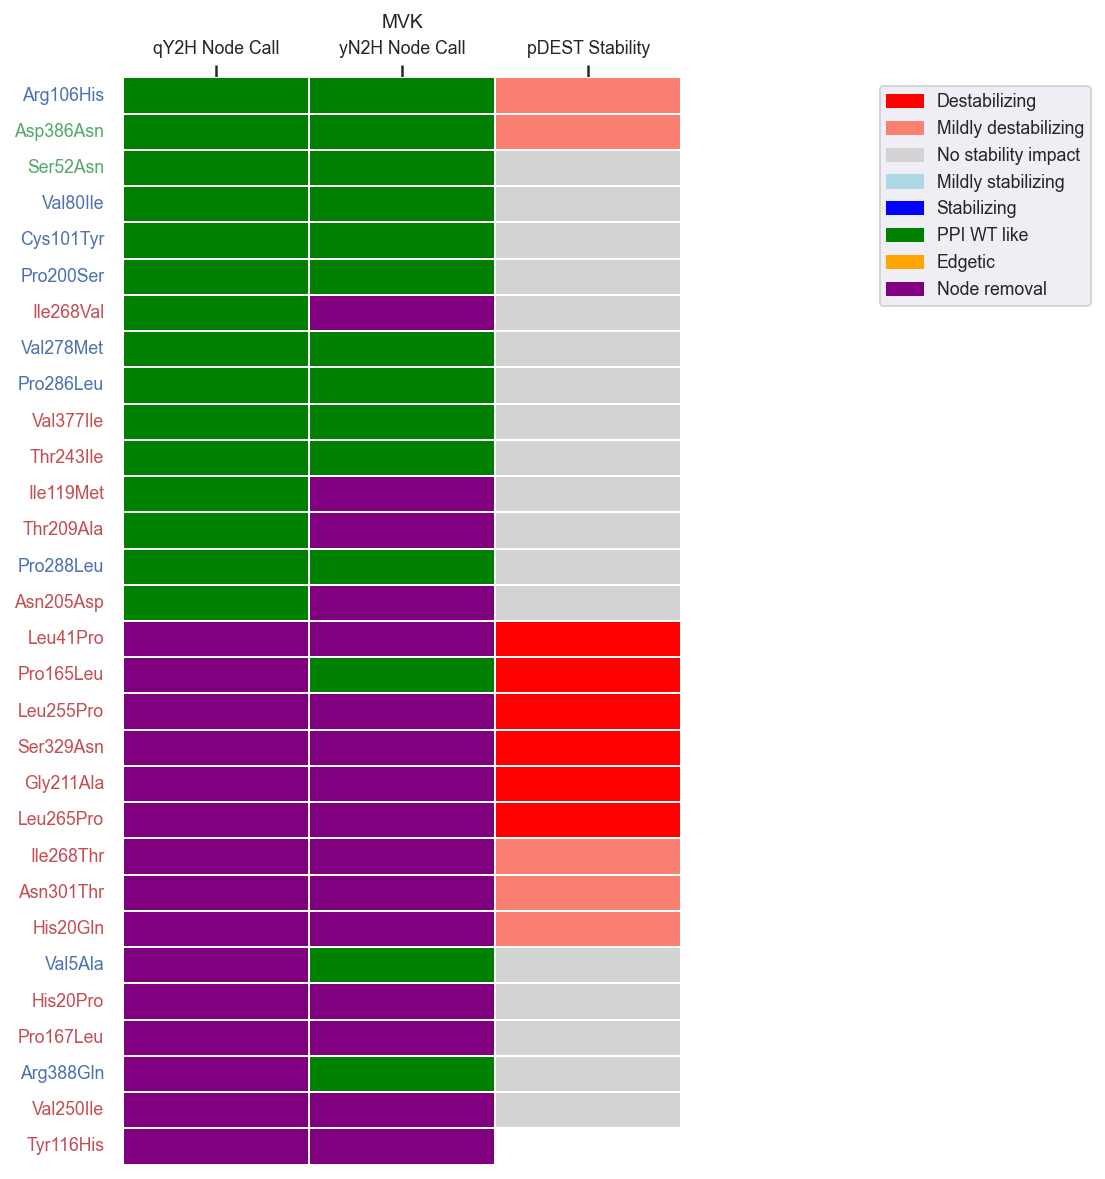

In [371]:
symbol = 'MVK'
print(symbol)

from matplotlib.colors import LinearSegmentedColormap

col = ['aa_change', 'qY2H_node_call_int','yN2H','pdest_zcat']
df = gene_level_df.query(f"symbol == '{symbol}'")[col].set_index('aa_change').copy()

df.sort_values(by=['qY2H_node_call_int','pdest_zcat'], inplace=True)

df['qY2H Node Call'] =  df.qY2H_node_call_int.astype(float).T
df['yN2H Node Call'] = df.yN2H.apply(lambda x: np.nan if x != x else 5 if (281.0, 'decrease_ppi') in x else 3 if (281.0, 'no_perturbation') in x else np.nan).T
df['pDEST Stability'] =  df.pdest_zcat.astype(float).T

df.drop(columns=['qY2H_node_call_int','yN2H','pdest_zcat'], inplace=True)


plt.figure(figsize=(5,10))
plt.title(f'{symbol}')
myColors = ('red','salmon','lightgray','lightblue','blue','green','orange','purple')
cmap = LinearSegmentedColormap.from_list('Custom', myColors, len(myColors))
cmap.set_bad("white") 
ax = sns.heatmap(data=df, cmap=cmap, cbar=False, linecolor='white', linewidths=1)

ax.xaxis.tick_top()
plt.ylabel('')

cs_color_d = {'VUS':'b','Pathogenic':'r', 'Conflicting':'b','Benign':'g','WT':'black'}
for tick_label in ax.get_yticklabels():
    aa_change = tick_label.get_text()
    cs = cs_d[(symbol,aa_change)]
    color = cs_color_d[cs] 
    tick_label.set_color(color)

import matplotlib.patches as mpatches
red_patch = mpatches.Patch(color='red', label='The red data')
blue_patch = mpatches.Patch(color='blue', label='The blue data')

impacts = ['Destabilizing','Mildly destabilizing', 'No stability impact', 'Mildly stabilizing', 'Stabilizing', 'PPI WT like', 'Edgetic', 'Node removal']

#plt.legend(handles=[red_patch, blue_patch])

plt.legend(handles=[mpatches.Patch(color=color, label=impact) for color,impact in zip(myColors,impacts)],  bbox_to_anchor=(1.75, 1))

plt.show()

SMAD3


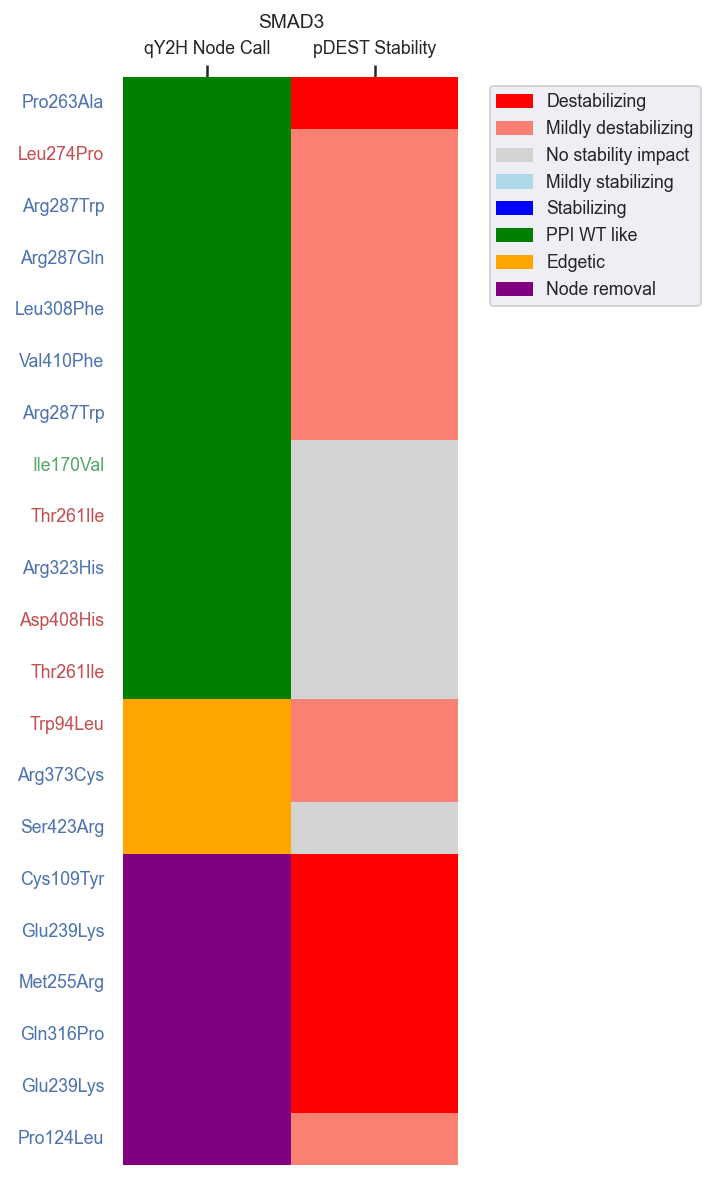

In [285]:
symbol = 'SMAD3'
print(symbol)

from matplotlib.colors import LinearSegmentedColormap

col = ['aa_change', 'qY2H_node_call_int','pdest_zcat']
df = gene_level_df.query(f"symbol == '{symbol}'")[col].set_index('aa_change')

df.sort_values(by=['qY2H_node_call_int','pdest_zcat'], inplace=True)

df['qY2H Node Call'] =  df.qY2H_node_call_int.astype(float).T
df['pDEST Stability'] =  df.pdest_zcat.astype(float).T

df.drop(columns=['qY2H_node_call_int','pdest_zcat'], inplace=True)


plt.figure(figsize=(3,10))
plt.title(f'{symbol}')
myColors = ('red','salmon','lightgray','lightblue','blue','green','orange','purple')
cmap = LinearSegmentedColormap.from_list('Custom', myColors, len(myColors))
cmap.set_bad("white") 
ax = sns.heatmap(data=df, cmap=cmap, cbar=False)

ax.xaxis.tick_top()
plt.ylabel('')

cs_color_d = {'VUS':'b','Pathogenic':'r', 'Conflicting':'b','Benign':'g','WT':'black'}
for tick_label in ax.get_yticklabels():
    aa_change = tick_label.get_text()
    cs = cs_d[(symbol,aa_change)]
    color = cs_color_d[cs] 
    tick_label.set_color(color)

import matplotlib.patches as mpatches
red_patch = mpatches.Patch(color='red', label='The red data')
blue_patch = mpatches.Patch(color='blue', label='The blue data')

impacts = ['Destabilizing','Mildly destabilizing', 'No stability impact', 'Mildly stabilizing', 'Stabilizing', 'PPI WT like', 'Edgetic', 'Node removal']

#plt.legend(handles=[red_patch, blue_patch])

plt.legend(handles=[mpatches.Patch(color=color, label=impact) for color,impact in zip(myColors,impacts)],  bbox_to_anchor=(1.75, 1))

plt.show()



AGXT


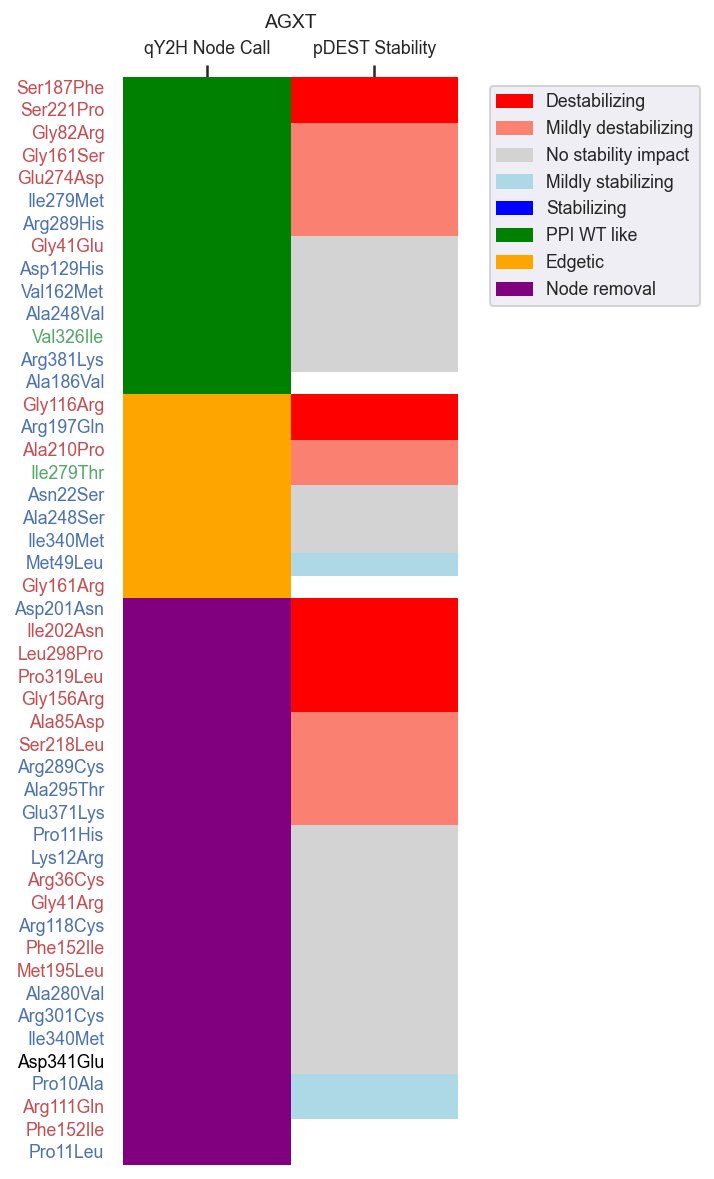

In [287]:
symbol = 'AGXT'
print(symbol)

from matplotlib.colors import LinearSegmentedColormap

col = ['aa_change', 'qY2H_node_call_int','pdest_zcat']
df = gene_level_df.query(f"symbol == '{symbol}'")[col].set_index('aa_change')

df.sort_values(by=['qY2H_node_call_int','pdest_zcat'], inplace=True)

df['qY2H Node Call'] =  df.qY2H_node_call_int.astype(float).T
df['pDEST Stability'] =  df.pdest_zcat.astype(float).T

df.drop(columns=['qY2H_node_call_int','pdest_zcat'], inplace=True)


plt.figure(figsize=(3,10))
plt.title(f'{symbol}')
myColors = ('red','salmon','lightgray','lightblue','blue','green','orange','purple')
cmap = LinearSegmentedColormap.from_list('Custom', myColors, len(myColors))
cmap.set_bad("white") 
ax = sns.heatmap(data=df, cmap=cmap, cbar=False)

ax.xaxis.tick_top()
plt.ylabel('')

cs_color_d = {'VUS':'b','Pathogenic':'r', 'Conflicting':'b','Benign':'g','WT':'black'}
for tick_label in ax.get_yticklabels():
    aa_change = tick_label.get_text()
    cs = cs_d[(symbol,aa_change)]
    color = cs_color_d[cs] if cs == cs else 'black'
    tick_label.set_color(color)

import matplotlib.patches as mpatches
red_patch = mpatches.Patch(color='red', label='The red data')
blue_patch = mpatches.Patch(color='blue', label='The blue data')

impacts = ['Destabilizing','Mildly destabilizing', 'No stability impact', 'Mildly stabilizing', 'Stabilizing', 'PPI WT like', 'Edgetic', 'Node removal']

#plt.legend(handles=[red_patch, blue_patch])

plt.legend(handles=[mpatches.Patch(color=color, label=impact) for color,impact in zip(myColors,impacts)],  bbox_to_anchor=(1.75, 1))

plt.show()



## MVK Table

In [293]:
summary_df = pd.read_csv('../../../edgotyping_data_analysis/clinvar_analysis/data_20220608/variant_summary.txt',sep='\t',skiprows=0, low_memory=False)
summary_df = summary_df[summary_df.Assembly == 'GRCh38'].copy()
summary_df.rename(columns={w:w.replace('#','').replace('(','').replace(')','').replace('/','') for w in summary_df.columns},inplace=True)
summary_df.head()

,AlleleID,Type,Name,GeneID,GeneSymbol,HGNC_ID,ClinicalSignificance,ClinSigSimple,LastEvaluated,RS dbSNP,nsvesv dbVar,RCVaccession,PhenotypeIDS,PhenotypeList,Origin,OriginSimple,Assembly,ChromosomeAccession,Chromosome,Start,Stop,ReferenceAllele,AlternateAllele,Cytogenetic,ReviewStatus,NumberSubmitters,Guidelines,TestedInGTR,OtherIDs,SubmitterCategories,VariationID,PositionVCF,ReferenceAlleleVCF,AlternateAlleleVCF
1,15041,Indel,NM_014855.3(AP5Z1):c.80_83delinsTGCTGTAAACTGTA...,9907,AP5Z1,HGNC:22197,Pathogenic,1,-,397704705,-,RCV000000012,"MONDO:MONDO:0013342,MedGen:C3150901,OMIM:61364...",Hereditary spastic paraplegia 48,germline;unknown,germline,GRCh38,NC_000007.14,7,4781213,4781216,na,na,7p22.1,"criteria provided, single submitter",2,-,N,"ClinGen:CA215070,OMIM:613653.0001",3,2,4781213,GGAT,TGCTGTAAACTGTAACTGTAAA
3,15042,Deletion,NM_014855.3(AP5Z1):c.1413_1426del (p.Leu473fs),9907,AP5Z1,HGNC:22197,Pathogenic,1,"Jun 29, 2010",397704709,-,RCV000000013,"MONDO:MONDO:0013342,MedGen:C3150901,OMIM:61364...",Hereditary spastic paraplegia 48,germline,germline,GRCh38,NC_000007.14,7,4787730,4787743,na,na,7p22.1,no assertion criteria provided,1,-,N,"ClinGen:CA215072,OMIM:613653.0002",1,3,4787729,GCTGCTGGACCTGCC,G
5,15043,single nucleotide variant,NM_014630.3(ZNF592):c.3136G>A (p.Gly1046Arg),9640,ZNF592,HGNC:28986,Uncertain significance,0,"Jun 29, 2015",150829393,-,RCV000000014,"MONDO:MONDO:0033005,MedGen:C4551772,OMIM:25130...",Galloway-Mowat syndrome 1,germline,germline,GRCh38,NC_000015.10,15,84799209,84799209,na,na,15q25.3,no assertion criteria provided,1,-,N,"OMIM:613624.0001,ClinGen:CA210674,UniProtKB:Q9...",1,4,84799209,G,A
7,15044,single nucleotide variant,NM_017547.4(FOXRED1):c.694C>T (p.Gln232Ter),55572,FOXRED1,HGNC:26927,Pathogenic,1,"Dec 30, 2019",267606829,-,RCV000000015|RCV000578659|RCV001194045,"MONDO:MONDO:0032624,MedGen:C4748791,OMIM:61824...","Mitochondrial complex 1 deficiency, nuclear ty...",germline,germline,GRCh38,NC_000011.10,11,126275389,126275389,na,na,11q24.2,"criteria provided, multiple submitters, no con...",3,-,N,"ClinGen:CA113792,OMIM:613622.0001",3,5,126275389,C,T
9,15045,single nucleotide variant,NM_017547.4(FOXRED1):c.1289A>G (p.Asn430Ser),55572,FOXRED1,HGNC:26927,Pathogenic,1,"Oct 01, 2010",267606830,-,RCV000000016,"MONDO:MONDO:0032624,MedGen:C4748791,OMIM:618241","Mitochondrial complex 1 deficiency, nuclear ty...",germline,germline,GRCh38,NC_000011.10,11,126277517,126277517,na,na,11q24.2,no assertion criteria provided,1,-,N,"ClinGen:CA113794,UniProtKB:Q96CU9#VAR_064571,O...",1,6,126277517,A,G


In [331]:
col = ['Name', 'GeneSymbol', 'ClinicalSignificance', 'LastEvaluated', 'SubmitterCategories', 'VariationID','PhenotypeList']

cv_mvk = summary_df[summary_df.GeneSymbol == 'MVK'][col].copy()
cv_mvk['aa_change'] = cv_mvk.Name.apply(lambda x: np.nan if '(p.' not in x else x.split('(p.')[-1][:-1])

cv_mvk.head()

,Name,GeneSymbol,ClinicalSignificance,LastEvaluated,SubmitterCategories,VariationID,PhenotypeList,aa_change
21629,NM_000431.4(MVK):c.902A>C (p.Asn301Thr),MVK,Pathogenic,"Jul 05, 1992",1,11928,Mevalonic aciduria,Asn301Thr
21631,NM_000431.4(MVK):c.1129G>A (p.Val377Ile),MVK,Conflicting interpretations of pathogenicity,"Apr 19, 2022",3,11929,Hyperimmunoglobulin D with periodic fever|Hype...,Val377Ile
21633,NM_000431.4(MVK):c.1000G>A (p.Ala334Thr),MVK,Pathogenic,"Aug 23, 2021",3,11930,Mevalonic aciduria|Hyperimmunoglobulin D with ...,Ala334Thr
21635,NM_000431.4(MVK):c.59A>C (p.His20Pro),MVK,Pathogenic,"Oct 09, 2019",3,11931,Hyperimmunoglobulin D with periodic fever|Meva...,His20Pro
21637,NM_000431.4(MVK):c.803T>C (p.Ile268Thr),MVK,Pathogenic,"Nov 09, 2021",3,11932,Hyperimmunoglobulin D with periodic fever|Meva...,Ile268Thr


In [349]:
func_assay_table = GetDFv2('select * from bioinfo_georges.functional_assays_AGXT_MLH1_MVK', col=['orf_id','nt_change','aa_change','symbol','mut_id','clinical_significance','dest_pla','dest_well'])
func_assay_table = func_assay_table[func_assay_table.symbol == 'MVK'].copy()
print(len(func_assay_table))
func_assay_table = func_assay_table.merge(cv_mvk[cv_mvk.Name.str.contains('\(p.')], on='aa_change', how='left')
print(len(func_assay_table))
func_assay_table['clinvar_URL'] = func_assay_table.VariationID.apply(lambda x: np.nan if x != x else f'https://www.ncbi.nlm.nih.gov/clinvar/variation/{int(x)}')

func_assay_table.merge(gene_level_df, left_on=['orf_id','mut_id'], right_on=['db_orf_id','db_mut_id'])


col = ['db_orf_id', 'db_mut_id', 'qY2H', 'yN2H', 'mN2H', 'pdest_zscore',
       'pdest_zcat', 'qY2H_degree', 'qmN2H_degree', 'qyN2H_degree',
       'qY2H_node_call', 'qY2H_node_call_int']


print(len(func_assay_table))
func_assay_table = func_assay_table.merge(gene_level_df[col], left_on=['orf_id','mut_id'], right_on=['db_orf_id','db_mut_id'], how='left')
print(len(func_assay_table))
func_assay_table.drop(columns=['db_orf_id','db_mut_id'],inplace=True)

func_assay_table.head()

42
42
42
42


,orf_id,nt_change,aa_change,symbol,mut_id,clinical_significance,dest_pla,dest_well,Name,GeneSymbol,ClinicalSignificance,LastEvaluated,SubmitterCategories,VariationID,PhenotypeList,clinvar_URL,qY2H,yN2H,mN2H,pdest_zscore,pdest_zcat,qY2H_degree,qmN2H_degree,qyN2H_degree,qY2H_node_call,qY2H_node_call_int
0,281,155G>A,Ser52Asn,MVK,5,Benign,MVK_GDEh_1,A01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"{(281.0, 1.0, 1.0, 1.0)}","{(281.0, no_perturbation)}",{},0.144154,0.0,1.0,0.0,1.0,PPI WT like,3.0
1,281,1156G>A,Asp386Asn,MVK,28,Benign,MVK_GDEh_1,B01,NM_000431.4(MVK):c.1156G>A (p.Asp386Asn),MVK,Benign/Likely benign,"Nov 09, 2021",2.0,97571.0,Hyperimmunoglobulin D with periodic fever|Meva...,https://www.ncbi.nlm.nih.gov/clinvar/variation...,"{(281.0, 1.0, 1.0, 1.0)}","{(281.0, no_perturbation)}",{},-1.660505,-1.0,1.0,0.0,1.0,PPI WT like,3.0
2,281,238G>A,Val80Ile,MVK,6,Conflicting,MVK_GDEh_1,C01,NM_000431.4(MVK):c.238G>A (p.Val80Ile),MVK,Conflicting interpretations of pathogenicity,"Mar 01, 2022",2.0,97578.0,Hyperimmunoglobulin D with periodic fever|not ...,https://www.ncbi.nlm.nih.gov/clinvar/variation...,"{(281.0, 1.0, 1.0, 1.0)}","{(281.0, no_perturbation)}",{},-0.813608,0.0,1.0,0.0,1.0,PPI WT like,3.0
3,281,500C>T,Pro167Leu,MVK,13,Pathogenic,MVK_GDEh_1,D01,NM_000431.4(MVK):c.500C>T (p.Pro167Leu),MVK,Likely pathogenic,"Dec 23, 2016",3.0,39725.0,Hyperimmunoglobulin D with periodic fever|not ...,https://www.ncbi.nlm.nih.gov/clinvar/variation...,"{(281.0, 0.0, 1.0, 0.0)}","{(281.0, decrease_ppi)}",{},0.539184,0.0,1.0,0.0,1.0,Node Removal,5.0
4,281,902A>C,Asn301Thr,MVK,23,Pathogenic,MVK_GDEh_1,E01,NM_000431.4(MVK):c.902A>C (p.Asn301Thr),MVK,Pathogenic,"Jul 05, 1992",1.0,11928.0,Mevalonic aciduria,https://www.ncbi.nlm.nih.gov/clinvar/variation...,"{(281.0, 0.0, 1.0, 0.0)}","{(281.0, decrease_ppi)}",{},-1.951288,-1.0,1.0,0.0,1.0,Node Removal,5.0


In [373]:
func_assay_table.to_csv('MVK_edgotyping_data.tsv',sep='\t',index=False)

In [357]:
align = 0
not_aligned = 0
for yN2H, qY2H, nc in zip(func_assay_table.yN2H, func_assay_table.qY2H, func_assay_table.qY2H_node_call):
    print(yN2H,qY2H,nc)
    if nc == nc:
        if (281.0, 'no_perturbation') in yN2H and nc == 'PPI WT like':
            align += 1

        elif (281.0, 'decrease_ppi') in yN2H and nc == 'Node Removal':
            align += 1
        else:
            not_aligned += 1

align, not_aligned, align/(align+not_aligned)

{(281.0, 'no_perturbation')} {(281.0, 1.0, 1.0, 1.0)} PPI WT like
{(281.0, 'no_perturbation')} {(281.0, 1.0, 1.0, 1.0)} PPI WT like
{(281.0, 'no_perturbation')} {(281.0, 1.0, 1.0, 1.0)} PPI WT like
{(281.0, 'decrease_ppi')} {(281.0, 0.0, 1.0, 0.0)} Node Removal
{(281.0, 'decrease_ppi')} {(281.0, 0.0, 1.0, 0.0)} Node Removal
{(281.0, 'decrease_ppi')} {(281.0, 1.0, 1.0, 1.0)} PPI WT like
nan nan nan
nan nan nan
{(281.0, 'decrease_ppi')} {(281.0, 1.0, 1.0, 1.0)} PPI WT like
{(281.0, 'decrease_ppi')} {(281.0, 0.0, 1.0, 0.0)} Node Removal
nan nan nan
{(281.0, 'no_perturbation')} {(281.0, 1.0, 1.0, 1.0)} PPI WT like
{(281.0, 'decrease_ppi')} {(281.0, 0.0, 1.0, 0.0)} Node Removal
{(281.0, 'decrease_ppi')} {(281.0, 0.0, 1.0, 0.0)} Node Removal
nan nan nan
nan nan nan
nan nan nan
{(281.0, 'decrease_ppi')} {(281.0, 0.0, 1.0, 0.0)} Node Removal
nan nan nan
nan nan nan
nan nan nan
{(281.0, 'decrease_ppi')} {(281.0, 0.0, 1.0, 0.0)} Node Removal
{(281.0, 'decrease_ppi')} {(281.0, 0.0, 1.0, 0.0)} Nod

(22, 6, 0.7857142857142857)

In [352]:
xx = load_qY2H()

In [356]:
xx[xx.db_orf_id == 281]

,ad_orf_id,db_orf_id,db_mut_id,standard_batch,assay_id,LW,LWH1,LWH10,LWH25,LWA,LWAH1,sum_score,n_condition,allele_score_norm,wt_score_norm,valid
18,281,281,0,VUSAPWT1B1,1,"[4.0, 4.0, True]","[3.0, 0.0, 1]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]",1.0,5.0,0.2,0.2,True
1895,281,281,1,VUSAPWT1B1,1,"[4.0, 3.0, True]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]",0.0,5.0,0.0,0.2,True
1897,281,281,3,VUSAPWT1B1,1,"[3.75, 4.0, True]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]",0.0,5.0,0.0,0.2,True
1899,281,281,4,VUSAPWT1B1,1,"[3.0, 3.0, True]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]",0.0,5.0,0.0,0.2,True
1901,281,281,5,VUSAPWT1B1,1,"[3.0, 3.0, True]","[4.0, 0.0, 1]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]",1.0,5.0,0.2,0.2,True
1903,281,281,6,VUSAPWT1B1,1,"[4.0, 3.0, True]","[2.0, 0.0, 1]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]",1.0,5.0,0.2,0.2,True
1905,281,281,7,VUSAPWT1B1,1,"[3.5, 4.0, True]","[4.0, 0.0, 1]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]",1.0,5.0,0.2,0.2,True
1907,281,281,8,VUSAPWT1B1,1,"[4.0, 4.0, True]","[4.0, 0.0, 1]","[3.0, 0.0, 1]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]",2.0,5.0,0.4,0.2,True
1909,281,281,10,VUSAPWT1B1,1,"[3.75, 3.0, True]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]",0.0,5.0,0.0,0.2,True
1911,281,281,11,VUSAPWT1B1,1,"[3.0, 3.0, True]","[nan, 0.0, nan]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]",0.0,4.0,0.0,0.2,True


In [378]:
pdest_df[pdest_df.symbol=='MVK'].to_csv('MVK_pdest_all.tsv',sep='\t')

In [381]:
pdest_df[(pdest_df.symbol=='MVK')&(pdest_df.aa_change.isin(['Ala148Thr','Pro167Leu','Asn301Thr']))]

,avg_gfp,avg_mcherry,avg_GFP_mCherry_ratio,pla,well,coordinates,n_cells,db_orf_id,db_mut_id,node_type,nt_change,aa_change,clinical_significance,symbol,valid_well,z_pdest_empty,z_pdest_gfp,valid_gfp_mcherry_ratio,wt_GFP_mCherry_ratio,pdest_awr,pdest_zscore,pdest_zcat
64,7103.958941,6691.592082,1.625134,22,C07,"(22, 'C07')",8772,281.0,11.0,allele,442G>A,Ala148Thr,Pathogenic,MVK,True,88.513127,4.302752,NaN,1.904104,0.853490,-0.541823,0.0
166,5569.569727,3429.896955,2.368494,22,F09,"(22, 'F09')",10194,281.0,739.0,allele,500C>T,Pro167Leu,Pathogenic,MVK,True,129.312805,6.610141,NaN,1.904104,1.243889,0.572025,0.0
269,5148.414117,3087.703505,2.346577,22,E07,"(22, 'E07')",10470,281.0,13.0,allele,500C>T,Pro167Leu,Pathogenic,MVK,True,128.109844,6.542108,NaN,1.904104,1.232379,0.539184,0.0
316,2547.336827,5758.841378,0.684484,22,G08,"(22, 'G08')",8582,281.0,23.0,allele,902A>C,Asn301Thr,Pathogenic,MVK,True,36.885144,1.382978,NaN,1.904104,0.359479,-1.951288,-1.0
694,7005.364962,6327.367337,1.714965,22,C10,"(22, 'C10')",9059,281.0,200089.0,allele,442G>A,Ala148Thr,Pathogenic,MVK,True,93.443561,4.581588,NaN,1.904104,0.900668,-0.407220,0.0
1347,3516.199038,7392.875927,0.711200,22,H09,"(22, 'H09')",8477,281.0,763.0,allele,902A>C,Asn301Thr,Pathogenic,MVK,True,38.351450,1.465904,NaN,1.904104,0.373509,-1.911257,-1.0


In [384]:
col = ['avg_gfp','avg_mcherry','avg_GFP_mCherry_ratio','pla','well','coordinates','n_cells','db_orf_id','db_mut_id','node_type','nt_change','aa_change','clinical_significance','pdest_awr','pdest_zscore','pdest_zcat']


pdest_df[(pdest_df.symbol=='MVK')&(pdest_df.aa_change.isin(['Ala148Thr','Pro167Leu','Asn301Thr']))][col].sort_values(by='aa_change')


,avg_gfp,avg_mcherry,avg_GFP_mCherry_ratio,pla,well,coordinates,n_cells,db_orf_id,db_mut_id,node_type,nt_change,aa_change,clinical_significance,pdest_awr,pdest_zscore,pdest_zcat
64,7103.958941,6691.592082,1.625134,22,C07,"(22, 'C07')",8772,281.0,11.0,allele,442G>A,Ala148Thr,Pathogenic,0.853490,-0.541823,0.0
694,7005.364962,6327.367337,1.714965,22,C10,"(22, 'C10')",9059,281.0,200089.0,allele,442G>A,Ala148Thr,Pathogenic,0.900668,-0.407220,0.0
316,2547.336827,5758.841378,0.684484,22,G08,"(22, 'G08')",8582,281.0,23.0,allele,902A>C,Asn301Thr,Pathogenic,0.359479,-1.951288,-1.0
1347,3516.199038,7392.875927,0.711200,22,H09,"(22, 'H09')",8477,281.0,763.0,allele,902A>C,Asn301Thr,Pathogenic,0.373509,-1.911257,-1.0
166,5569.569727,3429.896955,2.368494,22,F09,"(22, 'F09')",10194,281.0,739.0,allele,500C>T,Pro167Leu,Pathogenic,1.243889,0.572025,0.0
269,5148.414117,3087.703505,2.346577,22,E07,"(22, 'E07')",10470,281.0,13.0,allele,500C>T,Pro167Leu,Pathogenic,1.232379,0.539184,0.0


In [382]:
pdest_df.columns

Index(['avg_gfp', 'avg_mcherry', 'avg_GFP_mCherry_ratio', 'pla', 'well',
       'coordinates', 'n_cells', 'db_orf_id', 'db_mut_id', 'node_type',
       'nt_change', 'aa_change', 'clinical_significance', 'symbol',
       'valid_well', 'z_pdest_empty', 'z_pdest_gfp', 'valid_gfp_mcherry_ratio',
       'wt_GFP_mCherry_ratio', 'pdest_awr', 'pdest_zscore', 'pdest_zcat'],
      dtype='object')